In [68]:
import sys

print(sys.executable)

d:\PersonalizedLearningSystem\.venv\Scripts\python.exe


In [69]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [70]:
from pathlib import Path
import pandas as pd

DATA_DIR = Path("../dataset/raw")

print("Dataset files:")
for file in DATA_DIR.iterdir():
    print(file.name)

Dataset files:
assessments.csv
courses.csv
OULAD.names
studentAssessment.csv
studentInfo.csv
studentRegistration.csv
studentVle.csv
vle.csv


In [71]:
files = [
    "courses.csv",
    "assessments.csv",
    "studentInfo.csv",
    "studentRegistration.csv",
    "studentAssessment.csv",
    "vle.csv"
]

for file in files:
    df = pd.read_csv(DATA_DIR / file)

    print("\n" + "=" * 60)
    print(file)
    print("Shape:", df.shape)
    print("Columns:", list(df.columns))


courses.csv
Shape: (22, 3)
Columns: ['code_module', 'code_presentation', 'module_presentation_length']

assessments.csv
Shape: (206, 6)
Columns: ['code_module', 'code_presentation', 'id_assessment', 'assessment_type', 'date', 'weight']

studentInfo.csv
Shape: (32593, 12)
Columns: ['code_module', 'code_presentation', 'id_student', 'gender', 'region', 'highest_education', 'imd_band', 'age_band', 'num_of_prev_attempts', 'studied_credits', 'disability', 'final_result']

studentRegistration.csv
Shape: (32593, 5)
Columns: ['code_module', 'code_presentation', 'id_student', 'date_registration', 'date_unregistration']

studentAssessment.csv
Shape: (173912, 5)
Columns: ['id_assessment', 'id_student', 'date_submitted', 'is_banked', 'score']

vle.csv
Shape: (6364, 6)
Columns: ['id_site', 'code_module', 'code_presentation', 'activity_type', 'week_from', 'week_to']


In [72]:
for file in [
    "courses.csv",
    "assessments.csv",
    "studentInfo.csv",
    "studentAssessment.csv",
    "vle.csv"
]:
    df = pd.read_csv(DATA_DIR / file)

    print("\n" + "=" * 70)
    print(file)
    display(df.head())


courses.csv


,code_module,code_presentation,module_presentation_length
0,AAA,2013J,268
1,AAA,2014J,269
2,BBB,2013J,268
3,BBB,2014J,262
4,BBB,2013B,240



assessments.csv


,code_module,code_presentation,id_assessment,assessment_type,date,weight
0,AAA,2013J,1752,TMA,19,10.0
1,AAA,2013J,1753,TMA,54,20.0
2,AAA,2013J,1754,TMA,117,20.0
3,AAA,2013J,1755,TMA,166,20.0
4,AAA,2013J,1756,TMA,215,30.0



studentInfo.csv


,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,disability,final_result
0,AAA,2013J,11391,M,East Anglian Region,HE Qualification,90-100%,55<=,0,240,N,Pass
1,AAA,2013J,28400,F,Scotland,HE Qualification,20-30%,35-55,0,60,N,Pass
2,AAA,2013J,30268,F,North Western Region,A Level or Equivalent,30-40%,35-55,0,60,Y,Withdrawn
3,AAA,2013J,31604,F,South East Region,A Level or Equivalent,50-60%,35-55,0,60,N,Pass
4,AAA,2013J,32885,F,West Midlands Region,Lower Than A Level,50-60%,0-35,0,60,N,Pass



studentAssessment.csv


,id_assessment,id_student,date_submitted,is_banked,score
0,1752,11391,18,0,78
1,1752,28400,22,0,70
2,1752,31604,17,0,72
3,1752,32885,26,0,69
4,1752,38053,19,0,79



vle.csv


,id_site,code_module,code_presentation,activity_type,week_from,week_to
0,546943,AAA,2013J,resource,?,?
1,546712,AAA,2013J,oucontent,?,?
2,546998,AAA,2013J,resource,?,?
3,546888,AAA,2013J,url,?,?
4,547035,AAA,2013J,resource,?,?


In [73]:
student_vle_path = DATA_DIR / "studentVle.csv"

# File size
file_size_mb = student_vle_path.stat().st_size / (1024 ** 2)

print(f"File size: {file_size_mb:.2f} MB")

# Sirf first 5 rows read karenge
student_vle_sample = pd.read_csv(
    student_vle_path,
    nrows=5
)

print("Shape of sample:", student_vle_sample.shape)
print("Columns:", list(student_vle_sample.columns))

display(student_vle_sample)

File size: 432.81 MB
Shape of sample: (5, 6)
Columns: ['code_module', 'code_presentation', 'id_student', 'id_site', 'date', 'sum_click']


,code_module,code_presentation,id_student,id_site,date,sum_click
0,AAA,2013J,28400,546652,-10,4
1,AAA,2013J,28400,546652,-10,1
2,AAA,2013J,28400,546652,-10,1
3,AAA,2013J,28400,546614,-10,11
4,AAA,2013J,28400,546714,-10,1


In [74]:
# Process studentVle.csv in chunks

student_vle_path = DATA_DIR / "studentVle.csv"

chunk_size = 100_000
student_vle_features = []

for chunk in pd.read_csv(student_vle_path, chunksize=chunk_size):

    # Aggregate learning behaviour per student
    chunk_features = (
        chunk.groupby("id_student")
        .agg(
            total_clicks=("sum_click", "sum"),
            unique_resources=("id_site", "nunique"),
            active_days=("date", "nunique"),
            first_activity_day=("date", "min"),
            last_activity_day=("date", "max")
        )
        .reset_index()
    )

    student_vle_features.append(chunk_features)

print(f"Processed {len(student_vle_features)} chunks.")

Processed 107 chunks.


In [75]:
# Combine chunk-level results correctly

student_vle_final = (
    pd.concat(student_vle_features, ignore_index=True)
    .groupby("id_student")
    .agg(
        total_clicks=("total_clicks", "sum"),
        first_activity_day=("first_activity_day", "min"),
        last_activity_day=("last_activity_day", "max")
    )
    .reset_index()
)

# Learning span
student_vle_final["learning_span_days"] = (
    student_vle_final["last_activity_day"]
    - student_vle_final["first_activity_day"]
)

print("Final shape:", student_vle_final.shape)

display(student_vle_final.head())

Final shape: (26074, 5)


,id_student,total_clicks,first_activity_day,last_activity_day,learning_span_days
0,6516,2791,-23,269,292
1,8462,656,-6,118,124
2,11391,934,-5,253,258
3,23629,161,-6,87,93
4,23698,910,-18,231,249


In [76]:
processed_dir = Path("../dataset/processed")
processed_dir.mkdir(exist_ok=True)

output_path = processed_dir / "student_vle_features.csv"

student_vle_final.to_csv(output_path, index=False)

print(f"Saved successfully: {output_path}")
print(f"Rows: {len(student_vle_final):,}")

Saved successfully: ..\dataset\processed\student_vle_features.csv
Rows: 26,074


In [77]:
# Load student assessment data

student_assessment = pd.read_csv(
    DATA_DIR / "studentAssessment.csv"
)

print("Shape:", student_assessment.shape)
display(student_assessment.head())


Shape: (173912, 5)


,id_assessment,id_student,date_submitted,is_banked,score
0,1752,11391,18,0,78
1,1752,28400,22,0,70
2,1752,31604,17,0,72
3,1752,32885,26,0,69
4,1752,38053,19,0,79


In [78]:
# ============================================
# CREATE STUDENT-LEVEL PERFORMANCE FEATURES
# ============================================

# Convert score to numeric
# Invalid/missing values become NaN
student_assessment["score"] = pd.to_numeric(
    student_assessment["score"],
    errors="coerce"
)

# Make sure submission date is numeric too
student_assessment["date_submitted"] = pd.to_numeric(
    student_assessment["date_submitted"],
    errors="coerce"
)

# Create student-level performance features
student_performance = (
    student_assessment
    .groupby("id_student")
    .agg(
        average_score=("score", "mean"),
        assessment_count=("score", "count"),
        min_score=("score", "min"),
        max_score=("score", "max"),
        average_submission_day=("date_submitted", "mean")
    )
    .reset_index()
)

# Round numerical values for readability
student_performance["average_score"] = (
    student_performance["average_score"].round(2)
)

student_performance["average_submission_day"] = (
    student_performance["average_submission_day"].round(2)
)

print("Shape:", student_performance.shape)

display(student_performance.head())

Shape: (23369, 6)


,id_student,average_score,assessment_count,min_score,max_score,average_submission_day
0,6516,61.80,5,48.0,77.0,111.60
1,8462,87.00,7,83.0,93.0,23.00
2,11391,82.00,5,78.0,85.0,112.40
3,23629,82.50,4,63.0,100.0,55.75
4,23698,74.44,9,56.0,94.0,133.44


In [79]:
print(student_assessment["score"].dtype)
print(student_assessment["score"].head())

float64
0    78.0
1    70.0
2    72.0
3    69.0
4    79.0
Name: score, dtype: float64


In [80]:
student_assessment["score"] = pd.to_numeric(
    student_assessment["score"],
    errors="coerce"
)

print("Score dtype:", student_assessment["score"].dtype)
print("Missing scores:", student_assessment["score"].isna().sum())

Score dtype: float64
Missing scores: 173


In [81]:
missing_scores = student_assessment[
    student_assessment["score"].isna()
]

print("Missing score rows:", len(missing_scores))

display(missing_scores.head(20))

Missing score rows: 173


,id_assessment,id_student,date_submitted,is_banked,score
215,1752,721259,22,0,NaN
937,1754,260355,127,0,NaN
2364,1760,2606802,180,0,NaN
3358,14984,186780,77,0,NaN
3914,14984,531205,26,0,NaN
3943,14984,534151,7,0,NaN
4206,14984,549713,84,0,NaN
4311,14984,554393,55,0,NaN
4753,14985,186780,77,0,NaN
5722,14986,33666,117,0,NaN


In [82]:
student_performance = (
    student_assessment
    .groupby("id_student")
    .agg(
        average_score=("score", "mean"),
        assessment_count=("score", "count"),
        min_score=("score", "min"),
        max_score=("score", "max"),
        average_submission_day=("date_submitted", "mean")
    )
    .reset_index()
)

student_performance["average_score"] = (
    student_performance["average_score"].round(2)
)

student_performance["average_submission_day"] = (
    student_performance["average_submission_day"].round(2)
)

print("Shape:", student_performance.shape)

display(student_performance.head())

Shape: (23369, 6)


,id_student,average_score,assessment_count,min_score,max_score,average_submission_day
0,6516,61.80,5,48.0,77.0,111.60
1,8462,87.00,7,83.0,93.0,23.00
2,11391,82.00,5,78.0,85.0,112.40
3,23629,82.50,4,63.0,100.0,55.75
4,23698,74.44,9,56.0,94.0,133.44


In [83]:
student_info = pd.read_csv(
    DATA_DIR / "studentInfo.csv"
)

print("studentInfo:", student_info.shape)
print("Performance:", student_performance.shape)
print("VLE:", student_vle_final.shape)

print("\nUnique students:")
print("studentInfo:", student_info["id_student"].nunique())
print("Performance:", student_performance["id_student"].nunique())
print("VLE:", student_vle_final["id_student"].nunique())

studentInfo: (32593, 12)
Performance: (23369, 6)
VLE: (26074, 5)

Unique students:
studentInfo: 28785
Performance: 23369
VLE: 26074


In [84]:
# Create course-aware VLE features

student_vle_course_features = []

for chunk in pd.read_csv(
    DATA_DIR / "studentVle.csv",
    chunksize=100_000
):
    chunk_features = (
        chunk
        .groupby(
            ["id_student", "code_module", "code_presentation"]
        )
        .agg(
            total_clicks=("sum_click", "sum"),
            unique_resources=("id_site", "nunique"),
            active_days=("date", "nunique"),
            first_activity_day=("date", "min"),
            last_activity_day=("date", "max")
        )
        .reset_index()
    )

    student_vle_course_features.append(chunk_features)

print(f"Processed {len(student_vle_course_features)} chunks.")

Processed 107 chunks.


In [85]:
# Combine all chunk-level course-aware features

student_vle_course = (
    pd.concat(student_vle_course_features, ignore_index=True)
    .groupby(
        ["id_student", "code_module", "code_presentation"]
    )
    .agg(
        total_clicks=("total_clicks", "sum"),
        first_activity_day=("first_activity_day", "min"),
        last_activity_day=("last_activity_day", "max")
    )
    .reset_index()
)

# Calculate learning span
student_vle_course["learning_span_days"] = (
    student_vle_course["last_activity_day"]
    - student_vle_course["first_activity_day"]
)

print("Shape:", student_vle_course.shape)

display(student_vle_course.head(10))

Shape: (29228, 7)


,id_student,code_module,code_presentation,total_clicks,first_activity_day,last_activity_day,learning_span_days
0,6516,AAA,2014J,2791,-23,269,292
1,8462,DDD,2013J,646,-6,118,124
2,8462,DDD,2014J,10,10,10,0
3,11391,AAA,2013J,934,-5,253,258
4,23629,BBB,2013B,161,-6,87,93
5,23698,CCC,2014J,910,-18,231,249
6,23798,BBB,2013J,590,-4,267,271
7,24186,GGG,2014B,184,-4,240,244
8,24213,DDD,2014B,1992,-11,237,248
9,24391,GGG,2013J,712,2,249,247


In [86]:
# Add course information to each student assessment

assessment_data = student_assessment.merge(
    assessments[
        [
            "id_assessment",
            "code_module",
            "code_presentation"
        ]
    ],
    on="id_assessment",
    how="left"
)

print("Shape:", assessment_data.shape)

display(assessment_data.head())

Shape: (173912, 7)


,id_assessment,id_student,date_submitted,is_banked,score,code_module,code_presentation
0,1752,11391,18,0,78.0,AAA,2013J
1,1752,28400,22,0,70.0,AAA,2013J
2,1752,31604,17,0,72.0,AAA,2013J
3,1752,32885,26,0,69.0,AAA,2013J
4,1752,38053,19,0,79.0,AAA,2013J


In [87]:
assessments = pd.read_csv(
    DATA_DIR / "assessments.csv"
)

print("Shape:", assessments.shape)
display(assessments.head())

Shape: (206, 6)


,code_module,code_presentation,id_assessment,assessment_type,date,weight
0,AAA,2013J,1752,TMA,19,10.0
1,AAA,2013J,1753,TMA,54,20.0
2,AAA,2013J,1754,TMA,117,20.0
3,AAA,2013J,1755,TMA,166,20.0
4,AAA,2013J,1756,TMA,215,30.0


In [88]:
student_performance_course = (
    assessment_data
    .groupby(
        ["id_student", "code_module", "code_presentation"]
    )
    .agg(
        average_score=("score", "mean"),
        assessment_count=("score", "count"),
        min_score=("score", "min"),
        max_score=("score", "max"),
        average_submission_day=("date_submitted", "mean")
    )
    .reset_index()
)

student_performance_course["average_score"] = (
    student_performance_course["average_score"].round(2)
)

student_performance_course["average_submission_day"] = (
    student_performance_course["average_submission_day"].round(2)
)

print("Shape:", student_performance_course.shape)

display(student_performance_course.head(10))

Shape: (25843, 8)


,id_student,code_module,code_presentation,average_score,assessment_count,min_score,max_score,average_submission_day
0,6516,AAA,2014J,61.80,5,48.0,77.0,111.60
1,8462,DDD,2013J,87.67,3,83.0,93.0,55.00
2,8462,DDD,2014J,86.50,4,83.0,93.0,-1.00
3,11391,AAA,2013J,82.00,5,78.0,85.0,112.40
4,23629,BBB,2013B,82.50,4,63.0,100.0,55.75
5,23698,CCC,2014J,74.44,9,56.0,94.0,133.44
6,23798,BBB,2013J,93.91,11,87.0,100.0,120.45
7,24186,GGG,2014B,62.50,8,40.0,80.0,160.62
8,24213,DDD,2014B,76.29,7,58.0,91.0,125.71
9,24391,GGG,2013J,88.89,9,80.0,100.0,152.78


In [89]:
learner_course_profile = student_performance_course.merge(
    student_vle_course,
    on=[
        "id_student",
        "code_module",
        "code_presentation"
    ],
    how="outer"
)

print("Shape:", learner_course_profile.shape)

display(learner_course_profile.head(10))

Shape: (29278, 12)


,id_student,code_module,code_presentation,average_score,assessment_count,min_score,max_score,average_submission_day,total_clicks,first_activity_day,last_activity_day,learning_span_days
0,6516,AAA,2014J,61.80,5.0,48.0,77.0,111.60,2791.0,-23.0,269.0,292.0
1,8462,DDD,2013J,87.67,3.0,83.0,93.0,55.00,646.0,-6.0,118.0,124.0
2,8462,DDD,2014J,86.50,4.0,83.0,93.0,-1.00,10.0,10.0,10.0,0.0
3,11391,AAA,2013J,82.00,5.0,78.0,85.0,112.40,934.0,-5.0,253.0,258.0
4,23629,BBB,2013B,82.50,4.0,63.0,100.0,55.75,161.0,-6.0,87.0,93.0
5,23698,CCC,2014J,74.44,9.0,56.0,94.0,133.44,910.0,-18.0,231.0,249.0
6,23798,BBB,2013J,93.91,11.0,87.0,100.0,120.45,590.0,-4.0,267.0,271.0
7,24186,GGG,2014B,62.50,8.0,40.0,80.0,160.62,184.0,-4.0,240.0,244.0
8,24213,DDD,2014B,76.29,7.0,58.0,91.0,125.71,1992.0,-11.0,237.0,248.0
9,24391,GGG,2013J,88.89,9.0,80.0,100.0,152.78,712.0,2.0,249.0,247.0


In [90]:
# Check missing values in learner-course profile

missing_summary = (
    learner_course_profile
    .isna()
    .sum()
    .sort_values(ascending=False)
)

print("Missing values:")
display(missing_summary)

Missing values:


average_score             3458
min_score                 3458
max_score                 3458
assessment_count          3435
average_submission_day    3435
total_clicks                50
last_activity_day           50
first_activity_day          50
learning_span_days          50
code_presentation            0
id_student                   0
code_module                  0
dtype: int64

In [91]:
has_performance = learner_course_profile["average_score"].notna()
has_vle = learner_course_profile["total_clicks"].notna()

print("Both Performance + VLE:", (has_performance & has_vle).sum())
print("Performance only:", (has_performance & ~has_vle).sum())
print("VLE only:", (~has_performance & has_vle).sum())
print("Neither:", (~has_performance & ~has_vle).sum())

Both Performance + VLE: 25770
Performance only: 50
VLE only: 3458
Neither: 0


In [92]:
vle = pd.read_csv(DATA_DIR / "vle.csv")

print("VLE shape:", vle.shape)
print("Activity types:")
print(vle["activity_type"].value_counts())

display(vle.head())

VLE shape: (6364, 6)
Activity types:
activity_type
resource          2660
subpage           1055
oucontent          996
url                886
forumng            194
quiz               127
page               102
oucollaborate       82
questionnaire       61
ouwiki              49
dataplus            28
externalquiz        26
homepage            22
glossary            21
ouelluminate        21
dualpane            20
repeatactivity       5
htmlactivity         4
sharedsubpage        3
folder               2
Name: count, dtype: int64


,id_site,code_module,code_presentation,activity_type,week_from,week_to
0,546943,AAA,2013J,resource,?,?
1,546712,AAA,2013J,oucontent,?,?
2,546998,AAA,2013J,resource,?,?
3,546888,AAA,2013J,url,?,?
4,547035,AAA,2013J,resource,?,?


In [93]:
# Prepare VLE resource lookup

vle_lookup = vle[
    [
        "id_site",
        "code_module",
        "code_presentation",
        "activity_type"
    ]
].copy()

print("VLE lookup shape:", vle_lookup.shape)
print("Unique resource IDs:", vle_lookup["id_site"].nunique())

display(vle_lookup.head())

VLE lookup shape: (6364, 4)
Unique resource IDs: 6364


,id_site,code_module,code_presentation,activity_type
0,546943,AAA,2013J,resource
1,546712,AAA,2013J,oucontent
2,546998,AAA,2013J,resource
3,546888,AAA,2013J,url
4,547035,AAA,2013J,resource


In [94]:
# Map student interactions to VLE activity types

student_resource_chunks = []

for chunk in pd.read_csv(
    DATA_DIR / "studentVle.csv",
    chunksize=100_000
):
    chunk = chunk.merge(
        vle_lookup,
        on=[
            "id_site",
            "code_module",
            "code_presentation"
        ],
        how="left"
    )

    chunk_features = (
        chunk
        .groupby(
            [
                "id_student",
                "code_module",
                "code_presentation",
                "activity_type"
            ]
        )
        .agg(
            total_clicks=("sum_click", "sum"),
            unique_resources=("id_site", "nunique")
        )
        .reset_index()
    )

    student_resource_chunks.append(chunk_features)

print(f"Processed {len(student_resource_chunks)} chunks.")

Processed 107 chunks.


In [95]:
student_resource_profile = (
    pd.concat(student_resource_chunks, ignore_index=True)
    .groupby(
        [
            "id_student",
            "code_module",
            "code_presentation",
            "activity_type"
        ]
    )
    .agg(
        total_clicks=("total_clicks", "sum"),
        unique_resources=("unique_resources", "sum")
    )
    .reset_index()
)

print("Shape:", student_resource_profile.shape)

display(student_resource_profile.head(10))

Shape: (240357, 6)


,id_student,code_module,code_presentation,activity_type,total_clicks,unique_resources
0,6516,AAA,2014J,dataplus,21,4
1,6516,AAA,2014J,forumng,451,11
2,6516,AAA,2014J,homepage,497,3
3,6516,AAA,2014J,oucontent,1505,65
4,6516,AAA,2014J,resource,31,17
5,6516,AAA,2014J,subpage,143,11
6,6516,AAA,2014J,url,143,7
7,8462,DDD,2013J,externalquiz,12,6
8,8462,DDD,2013J,forumng,36,5
9,8462,DDD,2013J,homepage,184,4


In [96]:
print(
    student_resource_profile["activity_type"]
    .value_counts()
)

activity_type
homepage          29185
subpage           28210
resource          27596
oucontent         26922
forumng           26006
url               23901
quiz              19973
oucollaborate     10890
ouwiki            10616
page               8728
glossary           6036
externalquiz       4882
questionnaire      4511
dualpane           3707
dataplus           2710
ouelluminate       2501
folder             1934
htmlactivity       1918
sharedsubpage       128
repeatactivity        3
Name: count, dtype: int64


In [97]:
# Convert activity types into feature columns

activity_click_features = (
    student_resource_profile
    .pivot_table(
        index=[
            "id_student",
            "code_module",
            "code_presentation"
        ],
        columns="activity_type",
        values="total_clicks",
        aggfunc="sum",
        fill_value=0
    )
    .reset_index()
)

# Remove the column name created by pivot_table
activity_click_features.columns.name = None

print("Shape:", activity_click_features.shape)

display(activity_click_features.head())

Shape: (29228, 23)


,id_student,code_module,code_presentation,dataplus,dualpane,externalquiz,folder,forumng,glossary,homepage,...,ouelluminate,ouwiki,page,questionnaire,quiz,repeatactivity,resource,sharedsubpage,subpage,url
0,6516,AAA,2014J,21,0,0,0,451,0,497,...,0,0,0,0,0,0,31,0,143,143
1,8462,DDD,2013J,0,0,12,0,36,0,184,...,0,18,0,0,0,0,70,0,227,23
2,8462,DDD,2014J,0,0,0,0,2,0,7,...,0,0,0,0,0,0,0,0,0,0
3,11391,AAA,2013J,0,0,0,0,193,0,138,...,0,0,0,0,0,0,13,0,32,5
4,23629,BBB,2013B,0,0,0,0,87,0,36,...,0,0,0,0,31,0,2,0,5,0


In [98]:
# Combine performance + learning behaviour + activity-type features

learner_course_ml = (
    student_performance_course
    .merge(
        student_vle_course,
        on=[
            "id_student",
            "code_module",
            "code_presentation"
        ],
        how="inner"
    )
    .merge(
        activity_click_features,
        on=[
            "id_student",
            "code_module",
            "code_presentation"
        ],
        how="left"
    )
)

print("Shape:", learner_course_ml.shape)

display(learner_course_ml.head())

Shape: (25793, 32)


,id_student,code_module,code_presentation,average_score,assessment_count,min_score,max_score,average_submission_day,total_clicks,first_activity_day,...,ouelluminate,ouwiki,page,questionnaire,quiz,repeatactivity,resource,sharedsubpage,subpage,url
0,6516,AAA,2014J,61.80,5,48.0,77.0,111.60,2791,-23,...,0,0,0,0,0,0,31,0,143,143
1,8462,DDD,2013J,87.67,3,83.0,93.0,55.00,646,-6,...,0,18,0,0,0,0,70,0,227,23
2,8462,DDD,2014J,86.50,4,83.0,93.0,-1.00,10,10,...,0,0,0,0,0,0,0,0,0,0
3,11391,AAA,2013J,82.00,5,78.0,85.0,112.40,934,-5,...,0,0,0,0,0,0,13,0,32,5
4,23629,BBB,2013B,82.50,4,63.0,100.0,55.75,161,-6,...,0,0,0,0,31,0,2,0,5,0


In [99]:
student_info = pd.read_csv(
    DATA_DIR / "studentInfo.csv"
)

student_context = student_info[
    [
        "id_student",
        "code_module",
        "code_presentation",
        "gender",
        "region",
        "highest_education",
        "imd_band",
        "age_band",
        "num_of_prev_attempts",
        "studied_credits",
        "disability"
    ]
].copy()

print("Student context shape:", student_context.shape)

display(student_context.head())

Student context shape: (32593, 11)


,id_student,code_module,code_presentation,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,disability
0,11391,AAA,2013J,M,East Anglian Region,HE Qualification,90-100%,55<=,0,240,N
1,28400,AAA,2013J,F,Scotland,HE Qualification,20-30%,35-55,0,60,N
2,30268,AAA,2013J,F,North Western Region,A Level or Equivalent,30-40%,35-55,0,60,Y
3,31604,AAA,2013J,F,South East Region,A Level or Equivalent,50-60%,35-55,0,60,N
4,32885,AAA,2013J,F,West Midlands Region,Lower Than A Level,50-60%,0-35,0,60,N


In [100]:
# Build the final learner-course dataset

learner_course_dataset = learner_course_ml.merge(
    student_context,
    on=[
        "id_student",
        "code_module",
        "code_presentation"
    ],
    how="left"
)

print("Final shape:", learner_course_dataset.shape)

display(learner_course_dataset.head())

Final shape: (25793, 40)


,id_student,code_module,code_presentation,average_score,assessment_count,min_score,max_score,average_submission_day,total_clicks,first_activity_day,...,subpage,url,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,disability
0,6516,AAA,2014J,61.80,5,48.0,77.0,111.60,2791,-23,...,143,143,M,Scotland,HE Qualification,80-90%,55<=,0,60,N
1,8462,DDD,2013J,87.67,3,83.0,93.0,55.00,646,-6,...,227,23,M,London Region,HE Qualification,30-40%,55<=,0,90,N
2,8462,DDD,2014J,86.50,4,83.0,93.0,-1.00,10,10,...,0,0,M,London Region,HE Qualification,30-40%,55<=,1,60,N
3,11391,AAA,2013J,82.00,5,78.0,85.0,112.40,934,-5,...,32,5,M,East Anglian Region,HE Qualification,90-100%,55<=,0,240,N
4,23629,BBB,2013B,82.50,4,63.0,100.0,55.75,161,-6,...,5,0,F,East Anglian Region,Lower Than A Level,20-30%,0-35,2,60,N


In [101]:
print("Dataset shape:", learner_course_dataset.shape)

print("\nData types:")
display(learner_course_dataset.dtypes)

print("\nMissing values:")
display(
    learner_course_dataset
    .isna()
    .sum()
    .sort_values(ascending=False)
)

Dataset shape: (25793, 40)

Data types:


id_student                  int64
code_module                   str
code_presentation             str
average_score             float64
assessment_count            int64
min_score                 float64
max_score                 float64
average_submission_day    float64
total_clicks                int64
first_activity_day          int64
last_activity_day           int64
learning_span_days          int64
dataplus                    int64
dualpane                    int64
externalquiz                int64
folder                      int64
forumng                     int64
glossary                    int64
homepage                    int64
htmlactivity                int64
oucollaborate               int64
oucontent                   int64
ouelluminate                int64
ouwiki                      int64
page                        int64
questionnaire               int64
quiz                        int64
repeatactivity              int64
resource                    int64
sharedsubpage 


Missing values:


average_score             23
min_score                 23
max_score                 23
id_student                 0
code_presentation          0
code_module                0
assessment_count           0
average_submission_day     0
total_clicks               0
first_activity_day         0
last_activity_day          0
learning_span_days         0
dataplus                   0
dualpane                   0
externalquiz               0
folder                     0
forumng                    0
glossary                   0
homepage                   0
htmlactivity               0
oucollaborate              0
oucontent                  0
ouelluminate               0
ouwiki                     0
page                       0
questionnaire              0
quiz                       0
repeatactivity             0
resource                   0
sharedsubpage              0
subpage                    0
url                        0
gender                     0
region                     0
highest_educat

In [102]:
numeric_columns = learner_course_dataset.select_dtypes(
    include="number"
).columns

display(
    learner_course_dataset[numeric_columns].describe().T
)

,count,mean,std,min,25%,50%,75%,max
id_student,25793.0,708549.257667,554333.402942,6516.0,505722.000,589295.00,642883.00,2698588.0
average_score,25770.0,72.783618,16.370623,0.0,64.735,76.00,84.56,100.0
assessment_count,25793.0,6.729423,3.773267,0.0,4.000,7.00,10.00,14.0
min_score,25770.0,55.670237,22.201527,0.0,42.000,60.00,72.00,100.0
max_score,25770.0,86.562941,17.088062,0.0,80.000,92.00,100.00,100.0
average_submission_day,25793.0,98.321058,42.953156,-4.0,68.000,108.67,125.75,351.6
total_clicks,25793.0,1522.873028,1778.435282,1.0,392.000,907.00,1991.00,24139.0
first_activity_day,25793.0,-8.631373,12.419828,-25.0,-17.000,-10.00,-4.00,234.0
last_activity_day,25793.0,197.895282,73.463484,-24.0,156.000,233.00,246.00,269.0
learning_span_days,25793.0,206.526655,75.794113,0.0,162.000,240.00,258.00,293.0


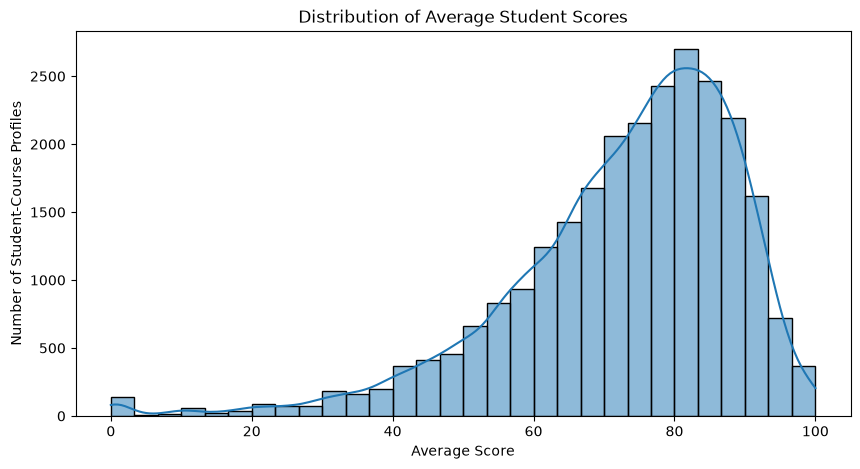

In [103]:
plt.figure(figsize=(10, 5))

sns.histplot(
    learner_course_dataset["average_score"].dropna(),
    bins=30,
    kde=True
)

plt.title("Distribution of Average Student Scores")
plt.xlabel("Average Score")
plt.ylabel("Number of Student-Course Profiles")
plt.show()

In [104]:
import matplotlib.pyplot as plt
import seaborn as sns

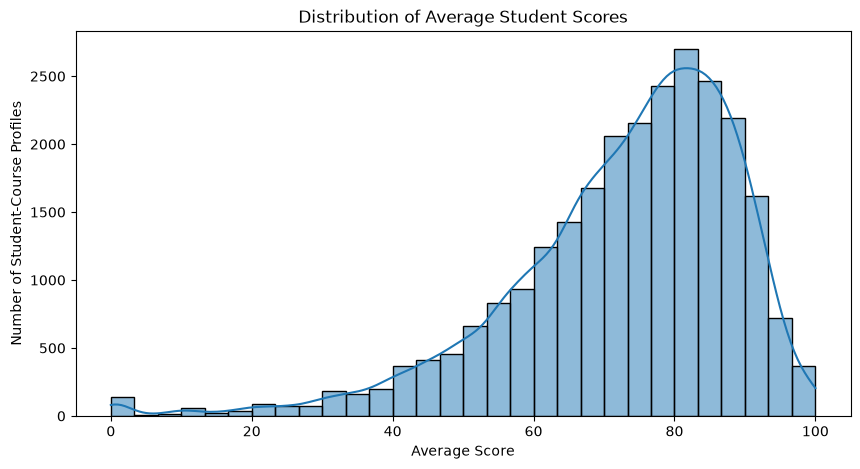

In [105]:
plt.figure(figsize=(10, 5))

sns.histplot(
    learner_course_dataset["average_score"].dropna(),
    bins=30,
    kde=True
)

plt.title("Distribution of Average Student Scores")
plt.xlabel("Average Score")
plt.ylabel("Number of Student-Course Profiles")
plt.show()

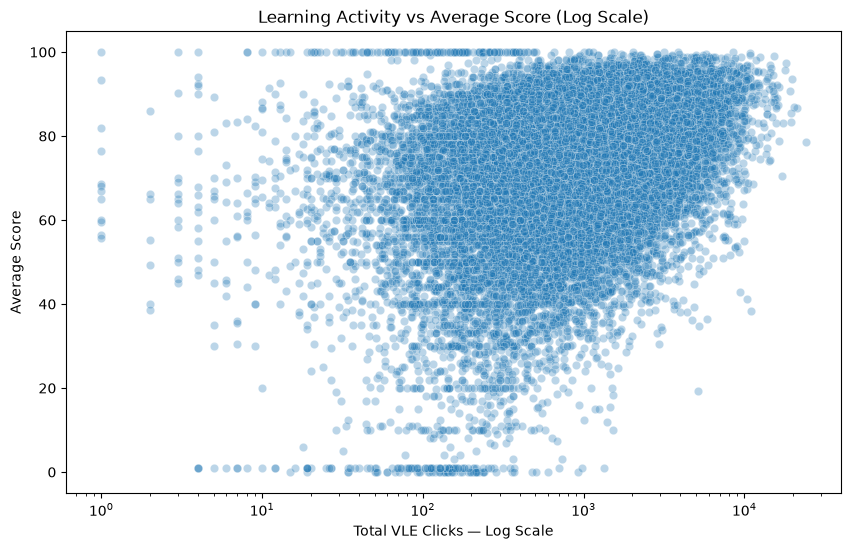

In [106]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=learner_course_dataset,
    x="total_clicks",
    y="average_score",
    alpha=0.3
)

plt.xscale("log")

plt.title("Learning Activity vs Average Score (Log Scale)")
plt.xlabel("Total VLE Clicks — Log Scale")
plt.ylabel("Average Score")
plt.show()

In [107]:
correlation = learner_course_dataset[
    ["total_clicks", "average_score"]
].corr()

display(correlation)

,total_clicks,average_score
total_clicks,1.000000,0.293253
average_score,0.293253,1.000000


In [108]:
activity_columns = [
    "dataplus",
    "dualpane",
    "externalquiz",
    "folder",
    "forumng",
    "glossary",
    "homepage",
    "htmlactivity",
    "oucollaborate",
    "oucontent",
    "ouelluminate",
    "ouwiki",
    "page",
    "questionnaire",
    "quiz",
    "repeatactivity",
    "resource",
    "sharedsubpage",
    "subpage",
    "url"
]

activity_totals = (
    learner_course_dataset[activity_columns]
    .sum()
    .sort_values(ascending=False)
)

display(activity_totals)

oucontent         11130185
forumng            7916465
quiz               6944607
homepage           6872911
subpage            3368975
resource           1089578
ouwiki              892098
url                 558498
oucollaborate       108009
glossary             87423
questionnaire        64731
externalquiz         63452
page                 61567
dataplus             47456
ouelluminate         38751
dualpane             20586
htmlactivity          8574
folder                5420
sharedsubpage          169
repeatactivity           9
dtype: int64

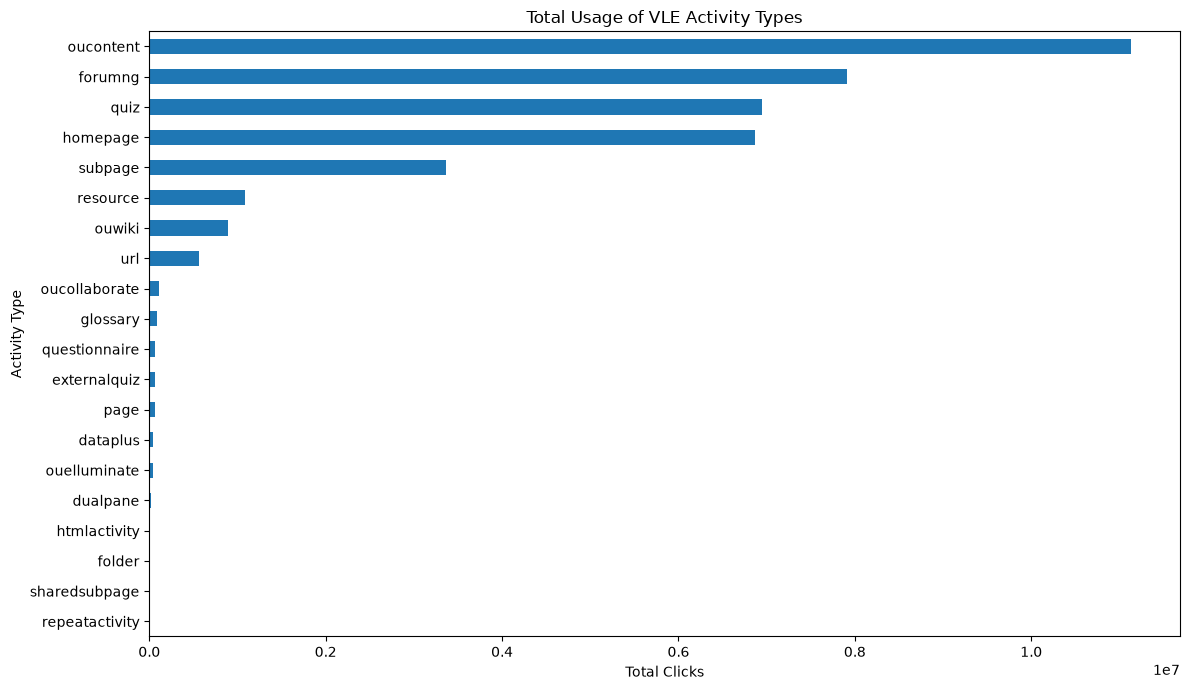

In [109]:
plt.figure(figsize=(12, 7))

activity_totals.sort_values().plot(kind="barh")

plt.title("Total Usage of VLE Activity Types")
plt.xlabel("Total Clicks")
plt.ylabel("Activity Type")
plt.tight_layout()
plt.show()

In [110]:
activity_score_corr = (
    learner_course_dataset[activity_columns + ["average_score"]]
    .corr()["average_score"]
    .drop("average_score")
    .sort_values(ascending=False)
)

display(activity_score_corr)

homepage          0.259958
forumng           0.223032
oucontent         0.203490
quiz              0.183904
ouwiki            0.183677
url               0.182688
subpage           0.177318
questionnaire     0.154301
dataplus          0.144879
page              0.136199
dualpane          0.129501
resource          0.085104
htmlactivity      0.072695
folder            0.069543
oucollaborate     0.055480
ouelluminate      0.040112
glossary          0.027835
sharedsubpage     0.022491
externalquiz      0.006081
repeatactivity    0.005938
Name: average_score, dtype: float64

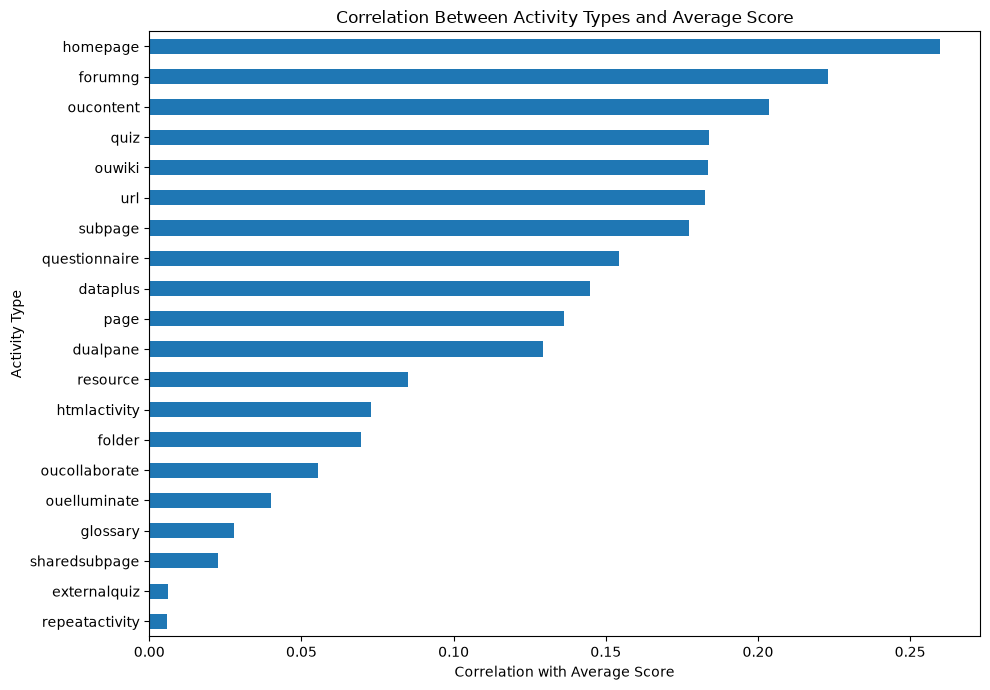

In [111]:
plt.figure(figsize=(10, 7))

activity_score_corr.sort_values().plot(kind="barh")

plt.title("Correlation Between Activity Types and Average Score")
plt.xlabel("Correlation with Average Score")
plt.ylabel("Activity Type")
plt.tight_layout()
plt.show()

In [112]:
print("VLE shape:", vle.shape)

display(vle.head())

print("\nActivity types:")
display(vle["activity_type"].value_counts())

VLE shape: (6364, 6)


,id_site,code_module,code_presentation,activity_type,week_from,week_to
0,546943,AAA,2013J,resource,?,?
1,546712,AAA,2013J,oucontent,?,?
2,546998,AAA,2013J,resource,?,?
3,546888,AAA,2013J,url,?,?
4,547035,AAA,2013J,resource,?,?



Activity types:


activity_type
resource          2660
subpage           1055
oucontent          996
url                886
forumng            194
quiz               127
page               102
oucollaborate       82
questionnaire       61
ouwiki              49
dataplus            28
externalquiz        26
homepage            22
glossary            21
ouelluminate        21
dualpane            20
repeatactivity       5
htmlactivity         4
sharedsubpage        3
folder               2
Name: count, dtype: int64

In [113]:
display(
    vle.groupby("activity_type")["id_site"]
       .count()
       .sort_values(ascending=False)
)

activity_type
resource          2660
subpage           1055
oucontent          996
url                886
forumng            194
quiz               127
page               102
oucollaborate       82
questionnaire       61
ouwiki              49
dataplus            28
externalquiz        26
homepage            22
glossary            21
ouelluminate        21
dualpane            20
repeatactivity       5
htmlactivity         4
sharedsubpage        3
folder               2
Name: id_site, dtype: int64

In [114]:
print("Missing week_from:")
print((vle["week_from"] == "?").sum())

print("\nMissing week_to:")
print((vle["week_to"] == "?").sum())

Missing week_from:
5243

Missing week_to:
5243


In [115]:
print("\nPercentage missing:")

print(
    "week_from:",
    round((vle["week_from"] == "?").mean() * 100, 2),
    "%"
)

print(
    "week_to:",
    round((vle["week_to"] == "?").mean() * 100, 2),
    "%"
)


Percentage missing:
week_from: 82.39 %
week_to: 82.39 %


In [116]:
resources_per_course = (
    vle.groupby(
        ["code_module", "code_presentation"]
    )["id_site"]
    .nunique()
    .sort_values(ascending=False)
)

display(resources_per_course)

code_module  code_presentation
FFF          2013J                529
             2013B                508
             2014B                478
DDD          2013J                462
             2014B                453
FFF          2014J                452
DDD          2013B                428
             2014J                365
BBB          2013J                321
             2013B                315
             2014B                311
CCC          2014J                223
AAA          2013J                211
BBB          2014J                207
AAA          2014J                202
CCC          2014B                196
GGG          2013J                137
             2014B                124
EEE          2014J                115
             2013J                112
             2014B                109
GGG          2014J                106
Name: id_site, dtype: int64

In [117]:
sample_vle = vle[
    [
        "id_site",
        "code_module",
        "code_presentation",
        "activity_type"
    ]
].head(10)

display(sample_vle)

,id_site,code_module,code_presentation,activity_type
0,546943,AAA,2013J,resource
1,546712,AAA,2013J,oucontent
2,546998,AAA,2013J,resource
3,546888,AAA,2013J,url
4,547035,AAA,2013J,resource
5,546614,AAA,2013J,homepage
6,546897,AAA,2013J,url
7,546678,AAA,2013J,oucontent
8,546933,AAA,2013J,resource
9,546708,AAA,2013J,oucontent


In [118]:
student_vle_sample = pd.read_csv(
    "../dataset/raw/studentVle.csv",
    nrows=10
)

display(student_vle_sample)

,code_module,code_presentation,id_student,id_site,date,sum_click
0,AAA,2013J,28400,546652,-10,4
1,AAA,2013J,28400,546652,-10,1
2,AAA,2013J,28400,546652,-10,1
3,AAA,2013J,28400,546614,-10,11
4,AAA,2013J,28400,546714,-10,1
5,AAA,2013J,28400,546652,-10,8
6,AAA,2013J,28400,546876,-10,2
7,AAA,2013J,28400,546688,-10,15
8,AAA,2013J,28400,546662,-10,17
9,AAA,2013J,28400,546890,-10,1


In [119]:
import pandas as pd

student_vle_path = "../dataset/raw/studentVle.csv"

interaction_chunks = []

for chunk in pd.read_csv(
    student_vle_path,
    chunksize=100_000
):

    # Same student + resource + date ko combine karna
    grouped = (
        chunk.groupby(
            [
                "id_student",
                "id_site",
                "code_module",
                "code_presentation",
                "date"
            ],
            as_index=False
        )["sum_click"]
        .sum()
    )

    interaction_chunks.append(grouped)

    print(f"Processed chunk: {len(interaction_chunks)}")

Processed chunk: 1
Processed chunk: 2
Processed chunk: 3
Processed chunk: 4
Processed chunk: 5
Processed chunk: 6
Processed chunk: 7
Processed chunk: 8
Processed chunk: 9
Processed chunk: 10
Processed chunk: 11
Processed chunk: 12
Processed chunk: 13
Processed chunk: 14
Processed chunk: 15
Processed chunk: 16
Processed chunk: 17
Processed chunk: 18
Processed chunk: 19
Processed chunk: 20
Processed chunk: 21
Processed chunk: 22
Processed chunk: 23
Processed chunk: 24
Processed chunk: 25
Processed chunk: 26
Processed chunk: 27
Processed chunk: 28
Processed chunk: 29
Processed chunk: 30
Processed chunk: 31
Processed chunk: 32
Processed chunk: 33
Processed chunk: 34
Processed chunk: 35
Processed chunk: 36
Processed chunk: 37
Processed chunk: 38
Processed chunk: 39
Processed chunk: 40
Processed chunk: 41
Processed chunk: 42
Processed chunk: 43
Processed chunk: 44
Processed chunk: 45
Processed chunk: 46
Processed chunk: 47
Processed chunk: 48
Processed chunk: 49
Processed chunk: 50
Processed

In [120]:
student_resource_interactions = pd.concat(
    interaction_chunks,
    ignore_index=True
)

print(
    "Interaction dataset shape:",
    student_resource_interactions.shape
)

display(student_resource_interactions.head())

Interaction dataset shape: (8459473, 6)


,id_student,id_site,code_module,code_presentation,date,sum_click
0,11391,546614,AAA,2013J,-5,7
1,11391,546614,AAA,2013J,0,10
2,11391,546614,AAA,2013J,1,9
3,11391,546614,AAA,2013J,2,3
4,11391,546614,AAA,2013J,6,1


In [121]:
student_resource_interactions = (
    student_resource_interactions
    .groupby(
        [
            "id_student",
            "id_site",
            "code_module",
            "code_presentation",
            "date"
        ],
        as_index=False
    )["sum_click"]
    .sum()
)

In [122]:
print(
    "Final interaction dataset shape:",
    student_resource_interactions.shape
)

display(student_resource_interactions.head(10))

Final interaction dataset shape: (8459320, 6)


,id_student,id_site,code_module,code_presentation,date,sum_click
0,6516,877011,AAA,2014J,204,6
1,6516,877011,AAA,2014J,209,8
2,6516,877011,AAA,2014J,218,9
3,6516,877012,AAA,2014J,0,38
4,6516,877012,AAA,2014J,5,12
5,6516,877012,AAA,2014J,10,5
6,6516,877012,AAA,2014J,11,11
7,6516,877012,AAA,2014J,13,6
8,6516,877012,AAA,2014J,14,7
9,6516,877012,AAA,2014J,19,2


In [123]:
resource_metadata = vle[
    [
        "id_site",
        "code_module",
        "code_presentation",
        "activity_type"
    ]
].drop_duplicates()

student_resource_interactions = student_resource_interactions.merge(
    resource_metadata,
    on=[
        "id_site",
        "code_module",
        "code_presentation"
    ],
    how="left"
)

print(
    "After resource metadata merge:",
    student_resource_interactions.shape
)

display(student_resource_interactions.head(10))

After resource metadata merge: (8459320, 7)


,id_student,id_site,code_module,code_presentation,date,sum_click,activity_type
0,6516,877011,AAA,2014J,204,6,forumng
1,6516,877011,AAA,2014J,209,8,forumng
2,6516,877011,AAA,2014J,218,9,forumng
3,6516,877012,AAA,2014J,0,38,forumng
4,6516,877012,AAA,2014J,5,12,forumng
5,6516,877012,AAA,2014J,10,5,forumng
6,6516,877012,AAA,2014J,11,11,forumng
7,6516,877012,AAA,2014J,13,6,forumng
8,6516,877012,AAA,2014J,14,7,forumng
9,6516,877012,AAA,2014J,19,2,forumng


In [124]:
print("Rows:", len(student_resource_interactions))

print(
    "Unique student-resource-date combinations:",
    student_resource_interactions[
        [
            "id_student",
            "id_site",
            "code_module",
            "code_presentation",
            "date"
        ]
    ].drop_duplicates().shape[0]
)

Rows: 8459320
Unique student-resource-date combinations: 8459320


In [125]:
print(
    "Missing activity_type:",
    student_resource_interactions["activity_type"].isna().sum()
)

Missing activity_type: 0


In [126]:
print("Rows:", len(student_resource_interactions))

print(
    "Unique interaction keys:",
    student_resource_interactions[
        [
            "id_student",
            "id_site",
            "code_module",
            "code_presentation",
            "date"
        ]
    ].drop_duplicates().shape[0]
)

print(
    "Missing activity_type:",
    student_resource_interactions["activity_type"].isna().sum()
)

Rows: 8459320
Unique interaction keys: 8459320
Missing activity_type: 0


In [127]:
student_interaction_counts = (
    student_resource_interactions
    .groupby("id_student")["id_site"]
    .nunique()
    .sort_values()
)

display(student_interaction_counts.describe())

count    26074.000000
mean        75.189691
std         61.960940
min          1.000000
25%         30.000000
50%         56.000000
75%        104.000000
max        579.000000
Name: id_site, dtype: float64

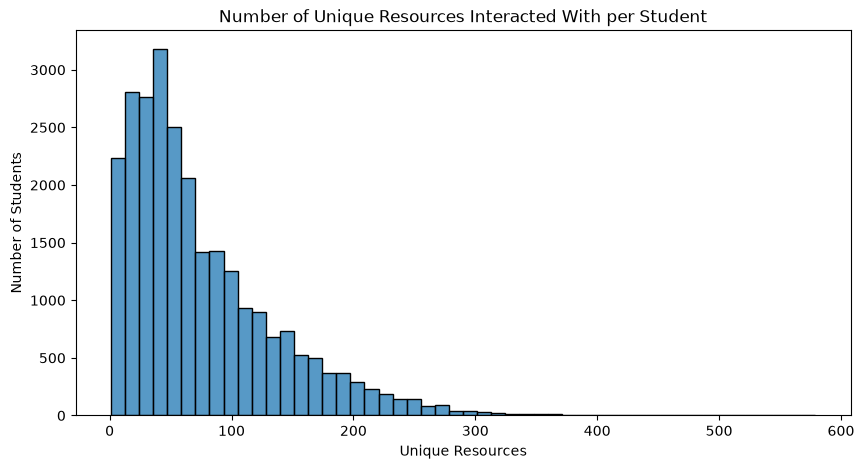

In [128]:
plt.figure(figsize=(10, 5))

sns.histplot(
    student_interaction_counts,
    bins=50
)

plt.title("Number of Unique Resources Interacted With per Student")
plt.xlabel("Unique Resources")
plt.ylabel("Number of Students")
plt.show()

In [129]:
for threshold in [2, 3, 5, 10, 20, 50]:
    count = (student_interaction_counts >= threshold).sum()

    print(
        f"Students with at least {threshold} unique resources:",
        count
    )

Students with at least 2 unique resources: 25864
Students with at least 3 unique resources: 25702
Students with at least 5 unique resources: 25344
Students with at least 10 unique resources: 24463
Students with at least 20 unique resources: 22270
Students with at least 50 unique resources: 14576


In [130]:
student_date_range = (
    student_resource_interactions
    .groupby("id_student")["date"]
    .agg(["min", "max", "count"])
)

student_date_range["span"] = (
    student_date_range["max"] -
    student_date_range["min"]
)

display(student_date_range.describe())

,min,max,count,span
count,26074.000000,26074.000000,26074.000000,26074.000000
mean,-8.484007,183.596188,324.435069,192.080195
std,12.625966,87.560213,338.560626,90.087025
min,-25.000000,-25.000000,1.000000,0.000000
25%,-17.000000,115.000000,83.000000,121.000000
50%,-10.000000,229.000000,213.000000,237.000000
75%,-4.000000,244.000000,458.000000,258.000000
max,238.000000,269.000000,4610.000000,294.000000


In [131]:
student_time = (
    student_resource_interactions
    .groupby("id_student")["date"]
    .agg(["min", "max"])
    .reset_index()
)

student_time["span"] = (
    student_time["max"] - student_time["min"]
)

student_time["cutoff"] = (
    student_time["min"] +
    0.8 * student_time["span"]
)

display(student_time.head(10))

,id_student,min,max,span,cutoff
0,6516,-23,269,292,210.6
1,8462,-6,118,124,93.2
2,11391,-5,253,258,201.4
3,23629,-6,87,93,68.4
4,23698,-18,231,249,181.2
5,23798,-4,267,271,212.8
6,24186,-4,240,244,191.2
7,24213,-11,237,248,187.4
8,24391,2,249,247,199.6
9,24734,-18,252,270,198.0


In [132]:
interactions_with_cutoff = student_resource_interactions.merge(
    student_time[
        ["id_student", "cutoff"]
    ],
    on="id_student",
    how="left"
)

In [133]:
history_interactions = interactions_with_cutoff[
    interactions_with_cutoff["date"]
    <= interactions_with_cutoff["cutoff"]
].copy()

future_interactions = interactions_with_cutoff[
    interactions_with_cutoff["date"]
    > interactions_with_cutoff["cutoff"]
].copy()

In [134]:
print("History:", history_interactions.shape)
print("Future:", future_interactions.shape)

History: (7148385, 8)
Future: (1310935, 8)


In [135]:
future_students = future_interactions["id_student"].nunique()

history_students = history_interactions["id_student"].nunique()

print("Students with history:", history_students)
print("Students with future:", future_students)

Students with history: 26074
Students with future: 25478


In [136]:
future_resource_counts = (
    future_interactions
    .groupby("id_student")["id_site"]
    .nunique()
)

display(future_resource_counts.describe())

count    25478.000000
mean        20.760970
std         19.798558
min          1.000000
25%          6.000000
50%         15.000000
75%         29.000000
max        294.000000
Name: id_site, dtype: float64

In [137]:
course_time = (
    student_resource_interactions
    .groupby(
        [
            "id_student",
            "code_module",
            "code_presentation"
        ]
    )["date"]
    .agg(["min", "max"])
    .reset_index()
)

course_time["span"] = (
    course_time["max"] - course_time["min"]
)

course_time["cutoff"] = (
    course_time["min"] +
    0.8 * course_time["span"]
)

display(course_time.head(10))

,id_student,code_module,code_presentation,min,max,span,cutoff
0,6516,AAA,2014J,-23,269,292,210.6
1,8462,DDD,2013J,-6,118,124,93.2
2,8462,DDD,2014J,10,10,0,10.0
3,11391,AAA,2013J,-5,253,258,201.4
4,23629,BBB,2013B,-6,87,93,68.4
5,23698,CCC,2014J,-18,231,249,181.2
6,23798,BBB,2013J,-4,267,271,212.8
7,24186,GGG,2014B,-4,240,244,191.2
8,24213,DDD,2014B,-11,237,248,187.4
9,24391,GGG,2013J,2,249,247,199.6


In [138]:
course_interactions = student_resource_interactions.merge(
    course_time[
        [
            "id_student",
            "code_module",
            "code_presentation",
            "cutoff"
        ]
    ],
    on=[
        "id_student",
        "code_module",
        "code_presentation"
    ],
    how="left"
)

In [139]:
print(course_interactions.shape)

display(course_interactions.head())

(8459320, 8)


,id_student,id_site,code_module,code_presentation,date,sum_click,activity_type,cutoff
0,6516,877011,AAA,2014J,204,6,forumng,210.6
1,6516,877011,AAA,2014J,209,8,forumng,210.6
2,6516,877011,AAA,2014J,218,9,forumng,210.6
3,6516,877012,AAA,2014J,0,38,forumng,210.6
4,6516,877012,AAA,2014J,5,12,forumng,210.6


In [140]:
history_interactions = course_interactions[
    course_interactions["date"]
    <= course_interactions["cutoff"]
].copy()

future_interactions = course_interactions[
    course_interactions["date"]
    > course_interactions["cutoff"]
].copy()

In [141]:
print("History:", history_interactions.shape)
print("Future:", future_interactions.shape)

History: (7107016, 8)
Future: (1352304, 8)


In [142]:
future_profiles = (
    future_interactions
    .groupby(
        [
            "id_student",
            "code_module",
            "code_presentation"
        ]
    )
    .agg(
        future_interactions=("id_site", "size"),
        future_unique_resources=("id_site", "nunique")
    )
    .reset_index()
)

display(future_profiles.head())

,id_student,code_module,code_presentation,future_interactions,future_unique_resources
0,6516,AAA,2014J,59,23
1,8462,DDD,2013J,15,7
2,11391,AAA,2013J,45,32
3,23629,BBB,2013B,6,4
4,23698,CCC,2014J,49,23


In [143]:
print("Future student-course profiles:", len(future_profiles))

Future student-course profiles: 28473


In [144]:
history_profile_stats = (
    history_interactions
    .groupby(
        [
            "id_student",
            "code_module",
            "code_presentation"
        ]
    )
    .agg(
        history_interactions=("id_site", "size"),
        history_unique_resources=("id_site", "nunique")
    )
    .reset_index()
)

display(history_profile_stats.head())

,id_student,code_module,code_presentation,history_interactions,history_unique_resources
0,6516,AAA,2014J,456,82
1,8462,DDD,2013J,269,123
2,8462,DDD,2014J,3,3
3,11391,AAA,2013J,122,44
4,23629,BBB,2013B,30,11


In [145]:
display(
    history_profile_stats[
        "history_unique_resources"
    ].describe()
)

count    29228.000000
mean        58.897222
std         50.006234
min          1.000000
25%         23.000000
50%         45.000000
75%         80.000000
max        368.000000
Name: history_unique_resources, dtype: float64

In [146]:
evaluation_profiles = history_profile_stats.merge(
    future_profiles,
    on=[
        "id_student",
        "code_module",
        "code_presentation"
    ],
    how="inner"
)

print(
    "Profiles with both history and future:",
    len(evaluation_profiles)
)

display(evaluation_profiles.head())

Profiles with both history and future: 28473


,id_student,code_module,code_presentation,history_interactions,history_unique_resources,future_interactions,future_unique_resources
0,6516,AAA,2014J,456,82,59,23
1,8462,DDD,2013J,269,123,15,7
2,11391,AAA,2013J,122,44,45,32
3,23629,BBB,2013B,30,11,6,4
4,23698,CCC,2014J,200,40,49,23


In [147]:
for threshold in [1, 2, 3, 5, 10, 20]:
    count = (
        evaluation_profiles[
            "history_unique_resources"
        ] >= threshold
    ).sum()

    print(
        f"History >= {threshold} unique resources: {count}"
    )

History >= 1 unique resources: 28473
History >= 2 unique resources: 28200
History >= 3 unique resources: 27983
History >= 5 unique resources: 27518
History >= 10 unique resources: 26289
History >= 20 unique resources: 23176


In [148]:
evaluation_profiles = evaluation_profiles[
    evaluation_profiles["history_unique_resources"] >= 5
].copy()

print(
    "Final evaluation profiles:",
    len(evaluation_profiles)
)

display(evaluation_profiles.head())

Final evaluation profiles: 27518


,id_student,code_module,code_presentation,history_interactions,history_unique_resources,future_interactions,future_unique_resources
0,6516,AAA,2014J,456,82,59,23
1,8462,DDD,2013J,269,123,15,7
2,11391,AAA,2013J,122,44,45,32
3,23629,BBB,2013B,30,11,6,4
4,23698,CCC,2014J,200,40,49,23


In [149]:
history_resource_sets = (
    history_interactions[
        [
            "id_student",
            "code_module",
            "code_presentation",
            "id_site"
        ]
    ]
    .groupby(
        [
            "id_student",
            "code_module",
            "code_presentation"
        ]
    )["id_site"]
    .apply(set)
    .reset_index(name="history_resources")
)

display(history_resource_sets.head())

,id_student,code_module,code_presentation,history_resources
0,6516,AAA,2014J,"{877056, 877058, 877059, 877061, 877062, 87706..."
1,8462,DDD,2013J,"{674306, 674314, 674322, 674325, 674332, 67434..."
2,8462,DDD,2014J,"{814280, 813701, 813710}"
3,11391,AAA,2013J,"{546688, 546691, 546692, 546694, 546702, 54671..."
4,23629,BBB,2013B,"{543113, 542891, 542892, 542797, 543055, 54286..."


In [150]:
future_resource_sets = (
    future_interactions[
        [
            "id_student",
            "code_module",
            "code_presentation",
            "id_site"
        ]
    ]
    .groupby(
        [
            "id_student",
            "code_module",
            "code_presentation"
        ]
    )["id_site"]
    .apply(set)
    .reset_index(name="future_resources")
)

display(future_resource_sets.head())

,id_student,code_module,code_presentation,future_resources
0,6516,AAA,2014J,"{877059, 877061, 877064, 877067, 877074, 87708..."
1,8462,DDD,2013J,"{674433, 674057, 673519, 674257, 674099, 67416..."
2,11391,AAA,2013J,"{546691, 546692, 546694, 546696, 546697, 54670..."
3,23629,BBB,2013B,"{542808, 542811, 542892, 542864}"
4,23698,CCC,2014J,"{989839, 1019025, 909330, 909090, 909091, 9092..."


In [151]:
evaluation_targets = evaluation_profiles[
    [
        "id_student",
        "code_module",
        "code_presentation"
    ]
].merge(
    history_resource_sets,
    on=[
        "id_student",
        "code_module",
        "code_presentation"
    ],
    how="left"
).merge(
    future_resource_sets,
    on=[
        "id_student",
        "code_module",
        "code_presentation"
    ],
    how="left"
)

In [152]:
evaluation_targets["future_unseen_resources"] = (
    evaluation_targets.apply(
        lambda row:
        row["future_resources"] - row["history_resources"],
        axis=1
    )
)

In [153]:
evaluation_targets["future_unseen_count"] = (
    evaluation_targets["future_unseen_resources"]
    .apply(len)
)

display(
    evaluation_targets[
        [
            "id_student",
            "code_module",
            "code_presentation",
            "future_unseen_count"
        ]
    ].head()
)

,id_student,code_module,code_presentation,future_unseen_count
0,6516,AAA,2014J,2
1,8462,DDD,2013J,2
2,11391,AAA,2013J,11
3,23629,BBB,2013B,0
4,23698,CCC,2014J,9


In [154]:
print(
    evaluation_targets["future_unseen_count"].describe()
)

count    27518.000000
mean         8.576459
std          9.502412
min          0.000000
25%          2.000000
50%          6.000000
75%         12.000000
max        263.000000
Name: future_unseen_count, dtype: float64


In [155]:
print(
    "Profiles with at least 1 future unseen resource:",
    (
        evaluation_targets["future_unseen_count"] >= 1
    ).sum()
)

Profiles with at least 1 future unseen resource: 23816


In [156]:
resource_catalog = vle[
    [
        "id_site",
        "code_module",
        "code_presentation",
        "activity_type"
    ]
].drop_duplicates()

print("Resource catalog shape:", resource_catalog.shape)

display(resource_catalog.head())

Resource catalog shape: (6364, 4)


,id_site,code_module,code_presentation,activity_type
0,546943,AAA,2013J,resource
1,546712,AAA,2013J,oucontent
2,546998,AAA,2013J,resource
3,546888,AAA,2013J,url
4,547035,AAA,2013J,resource


In [157]:
print(
    "Unique resource IDs:",
    resource_catalog["id_site"].nunique()
)

print(
    "Unique course-resource combinations:",
    resource_catalog[
        [
            "id_site",
            "code_module",
            "code_presentation"
        ]
    ].drop_duplicates().shape[0]
)

Unique resource IDs: 6364
Unique course-resource combinations: 6364


In [158]:
course_resources = (
    resource_catalog
    .groupby(["code_module", "code_presentation"])["id_site"]
    .apply(set)
    .reset_index(name="all_resources")
)

print("Course groups:", len(course_resources))
display(course_resources.head())

Course groups: 22


,code_module,code_presentation,all_resources
0,AAA,2013J,"{546871, 546872, 546873, 546874, 546876, 54687..."
1,AAA,2014J,"{877056, 877057, 877058, 877059, 877060, 87706..."
2,BBB,2013B,"{542792, 542794, 542795, 542796, 542797, 54279..."
3,BBB,2013J,"{703721, 703722, 703723, 703725, 703726, 70372..."
4,BBB,2014B,"{768330, 768331, 768332, 768333, 768334, 76833..."


In [159]:
evaluation_candidates = evaluation_targets.merge(
    course_resources,
    on=["code_module", "code_presentation"],
    how="left"
)

print("Evaluation profiles:", len(evaluation_candidates))
display(evaluation_candidates.head())

Evaluation profiles: 27518


,id_student,code_module,code_presentation,history_resources,future_resources,future_unseen_resources,future_unseen_count,all_resources
0,6516,AAA,2014J,"{877056, 877058, 877059, 877061, 877062, 87706...","{877059, 877061, 877064, 877067, 877074, 87708...","{877032, 877047}",2,"{877056, 877057, 877058, 877059, 877060, 87706..."
1,8462,DDD,2013J,"{674306, 674314, 674322, 674325, 674332, 67434...","{674433, 674057, 673519, 674257, 674099, 67416...","{674168, 674257}",2,"{673967, 673968, 673969, 673970, 673971, 67397..."
2,11391,AAA,2013J,"{546688, 546691, 546692, 546694, 546702, 54671...","{546691, 546692, 546694, 546696, 546697, 54670...","{546721, 546883, 546696, 546697, 546664, 54673...",11,"{546871, 546872, 546873, 546874, 546876, 54687..."
3,23629,BBB,2013B,"{543113, 542891, 542892, 542797, 543055, 54286...","{542808, 542811, 542892, 542864}",{},0,"{542792, 542794, 542795, 542796, 542797, 54279..."
4,23698,CCC,2014J,"{909321, 909323, 909325, 909071, 909327, 90933...","{989839, 1019025, 909330, 909090, 909091, 9092...","{909288, 909289, 909290, 909292, 909293, 90929...",9,"{937755, 909313, 909314, 909315, 909316, 90931..."


In [160]:
evaluation_candidates["candidate_resources"] = (
    evaluation_candidates["all_resources"]
    - evaluation_candidates["history_resources"]
)

In [161]:
evaluation_candidates["candidate_count"] = (
    evaluation_candidates["candidate_resources"].apply(len)
)

print(
    evaluation_candidates["candidate_count"].describe()
)

count    27518.000000
mean       260.641108
std        125.192991
min         21.000000
25%        149.000000
50%        281.000000
75%        362.000000
max        524.000000
Name: candidate_count, dtype: float64


In [162]:
activity_distribution = (
    history_interactions
    .groupby(
        ["id_student", "code_module", "code_presentation", "activity_type"]
    )["sum_click"]
    .sum()
    .reset_index()
)

display(activity_distribution.head(20))

,id_student,code_module,code_presentation,activity_type,sum_click
0,6516,AAA,2014J,dataplus,21
1,6516,AAA,2014J,forumng,415
2,6516,AAA,2014J,homepage,434
3,6516,AAA,2014J,oucontent,1248
4,6516,AAA,2014J,resource,31
5,6516,AAA,2014J,subpage,140
6,6516,AAA,2014J,url,139
7,8462,DDD,2013J,externalquiz,12
8,8462,DDD,2013J,forumng,36
9,8462,DDD,2013J,homepage,166


In [163]:
print("Rows:", len(activity_distribution))
print("Activity types:", activity_distribution["activity_type"].nunique())

display(
    activity_distribution
    .groupby("activity_type")["sum_click"]
    .sum()
    .sort_values(ascending=False)
)

Rows: 232173
Activity types: 20


activity_type
oucontent         9303019
forumng           6905716
homepage          5945168
quiz              4882699
subpage           2857507
resource           913589
ouwiki             872818
url                511199
oucollaborate       76780
glossary            76177
questionnaire       58372
page                54772
externalquiz        45255
ouelluminate        35857
dataplus            32015
dualpane            18634
htmlactivity         8968
folder               1581
sharedsubpage         159
repeatactivity          9
Name: sum_click, dtype: int64

In [164]:
learner_activity_profile = (
    history_interactions
    .groupby(
        [
            "id_student",
            "code_module",
            "code_presentation",
            "activity_type"
        ]
    )["sum_click"]
    .sum()
    .reset_index(name="activity_clicks")
)

print("Shape:", learner_activity_profile.shape)

display(learner_activity_profile.head(20))

Shape: (232173, 5)


,id_student,code_module,code_presentation,activity_type,activity_clicks
0,6516,AAA,2014J,dataplus,21
1,6516,AAA,2014J,forumng,415
2,6516,AAA,2014J,homepage,434
3,6516,AAA,2014J,oucontent,1248
4,6516,AAA,2014J,resource,31
5,6516,AAA,2014J,subpage,140
6,6516,AAA,2014J,url,139
7,8462,DDD,2013J,externalquiz,12
8,8462,DDD,2013J,forumng,36
9,8462,DDD,2013J,homepage,166


In [165]:
learner_activity_profile["total_activity_clicks"] = (
    learner_activity_profile
    .groupby(
        ["id_student", "code_module", "code_presentation"]
    )["activity_clicks"]
    .transform("sum")
)

learner_activity_profile["activity_preference_score"] = (
    learner_activity_profile["activity_clicks"]
    / learner_activity_profile["total_activity_clicks"]
)

display(learner_activity_profile.head(20))

,id_student,code_module,code_presentation,activity_type,activity_clicks,total_activity_clicks,activity_preference_score
0,6516,AAA,2014J,dataplus,21,2428,0.008649
1,6516,AAA,2014J,forumng,415,2428,0.170923
2,6516,AAA,2014J,homepage,434,2428,0.178748
3,6516,AAA,2014J,oucontent,1248,2428,0.514003
4,6516,AAA,2014J,resource,31,2428,0.012768
5,6516,AAA,2014J,subpage,140,2428,0.057661
6,6516,AAA,2014J,url,139,2428,0.057249
7,8462,DDD,2013J,externalquiz,12,621,0.019324
8,8462,DDD,2013J,forumng,36,621,0.057971
9,8462,DDD,2013J,homepage,166,621,0.267311


In [166]:
resource_engagement = (
    history_interactions
    .groupby(
        [
            "code_module",
            "code_presentation",
            "id_site",
            "activity_type"
        ]
    )
    .agg(
        total_clicks=("sum_click", "sum"),
        unique_learners=("id_student", "nunique")
    )
    .reset_index()
)

print("Shape:", resource_engagement.shape)

display(resource_engagement.head(20))

Shape: (6137, 6)


,code_module,code_presentation,id_site,activity_type,total_clicks,unique_learners
0,AAA,2013J,546614,homepage,118150,378
1,AAA,2013J,546644,forumng,907,68
2,AAA,2013J,546645,forumng,7363,283
3,AAA,2013J,546647,forumng,3769,188
4,AAA,2013J,546648,forumng,1826,119
5,AAA,2013J,546649,forumng,3287,121
6,AAA,2013J,546650,forumng,16959,202
7,AAA,2013J,546651,forumng,12903,187
8,AAA,2013J,546652,forumng,14504,344
9,AAA,2013J,546653,forumng,2271,143


In [167]:
resource_engagement["popularity_score"] = (
    resource_engagement
    .groupby(["code_module", "code_presentation"])["unique_learners"]
    .transform(
        lambda x: x / x.max()
    )
)

display(
    resource_engagement[
        [
            "code_module",
            "code_presentation",
            "id_site",
            "activity_type",
            "unique_learners",
            "popularity_score"
        ]
    ].head(20)
)

,code_module,code_presentation,id_site,activity_type,unique_learners,popularity_score
0,AAA,2013J,546614,homepage,378,1.000000
1,AAA,2013J,546644,forumng,68,0.179894
2,AAA,2013J,546645,forumng,283,0.748677
3,AAA,2013J,546647,forumng,188,0.497354
4,AAA,2013J,546648,forumng,119,0.314815
5,AAA,2013J,546649,forumng,121,0.320106
6,AAA,2013J,546650,forumng,202,0.534392
7,AAA,2013J,546651,forumng,187,0.494709
8,AAA,2013J,546652,forumng,344,0.910053
9,AAA,2013J,546653,forumng,143,0.378307


In [168]:
candidate_rows = evaluation_candidates[
    [
        "id_student",
        "code_module",
        "code_presentation",
        "candidate_resources"
    ]
].explode("candidate_resources")

candidate_rows = candidate_rows.rename(
    columns={"candidate_resources": "id_site"}
)

print("Candidate rows:", len(candidate_rows))

display(candidate_rows.head(10))

Candidate rows: 7172322


,id_student,code_module,code_presentation,id_site
0,6516,AAA,2014J,877057
0,6516,AAA,2014J,877060
0,6516,AAA,2014J,877063
0,6516,AAA,2014J,877066
0,6516,AAA,2014J,877069
0,6516,AAA,2014J,877072
0,6516,AAA,2014J,877075
0,6516,AAA,2014J,877076
0,6516,AAA,2014J,877085
0,6516,AAA,2014J,877087


In [169]:
candidate_rows = candidate_rows.merge(
    resource_catalog,
    on=[
        "id_site",
        "code_module",
        "code_presentation"
    ],
    how="left"
)

print(candidate_rows.shape)
display(candidate_rows.head(10))

(7172322, 5)


,id_student,code_module,code_presentation,id_site,activity_type
0,6516,AAA,2014J,877057,oucontent
1,6516,AAA,2014J,877060,oucontent
2,6516,AAA,2014J,877063,oucontent
3,6516,AAA,2014J,877066,oucontent
4,6516,AAA,2014J,877069,oucontent
5,6516,AAA,2014J,877072,oucontent
6,6516,AAA,2014J,877075,oucontent
7,6516,AAA,2014J,877076,oucontent
8,6516,AAA,2014J,877085,oucontent
9,6516,AAA,2014J,877087,oucontent


In [170]:
candidate_rows = candidate_rows.merge(
    resource_engagement[
        [
            "code_module",
            "code_presentation",
            "id_site",
            "popularity_score"
        ]
    ],
    on=[
        "code_module",
        "code_presentation",
        "id_site"
    ],
    how="left"
)

candidate_rows["popularity_score"] = (
    candidate_rows["popularity_score"].fillna(0)
)

display(candidate_rows.head(10))

,id_student,code_module,code_presentation,id_site,activity_type,popularity_score
0,6516,AAA,2014J,877057,oucontent,0.109244
1,6516,AAA,2014J,877060,oucontent,0.036415
2,6516,AAA,2014J,877063,oucontent,0.025210
3,6516,AAA,2014J,877066,oucontent,0.775910
4,6516,AAA,2014J,877069,oucontent,0.773109
5,6516,AAA,2014J,877072,oucontent,0.162465
6,6516,AAA,2014J,877075,oucontent,0.319328
7,6516,AAA,2014J,877076,oucontent,0.745098
8,6516,AAA,2014J,877085,oucontent,0.893557
9,6516,AAA,2014J,877087,oucontent,0.414566


In [171]:
candidate_rows = candidate_rows.merge(
    learner_activity_profile[
        [
            "id_student",
            "code_module",
            "code_presentation",
            "activity_type",
            "activity_preference_score"
        ]
    ],
    on=[
        "id_student",
        "code_module",
        "code_presentation",
        "activity_type"
    ],
    how="left"
)

candidate_rows["activity_preference_score"] = (
    candidate_rows["activity_preference_score"].fillna(0)
)

display(candidate_rows.head(10))

,id_student,code_module,code_presentation,id_site,activity_type,popularity_score,activity_preference_score
0,6516,AAA,2014J,877057,oucontent,0.109244,0.514003
1,6516,AAA,2014J,877060,oucontent,0.036415,0.514003
2,6516,AAA,2014J,877063,oucontent,0.025210,0.514003
3,6516,AAA,2014J,877066,oucontent,0.775910,0.514003
4,6516,AAA,2014J,877069,oucontent,0.773109,0.514003
5,6516,AAA,2014J,877072,oucontent,0.162465,0.514003
6,6516,AAA,2014J,877075,oucontent,0.319328,0.514003
7,6516,AAA,2014J,877076,oucontent,0.745098,0.514003
8,6516,AAA,2014J,877085,oucontent,0.893557,0.514003
9,6516,AAA,2014J,877087,oucontent,0.414566,0.514003


In [172]:
candidate_rows["recommendation_score"] = (
    0.7 * candidate_rows["activity_preference_score"]
    + 0.3 * candidate_rows["popularity_score"]
)

In [173]:
top_recommendations = (
    candidate_rows[
        candidate_rows["id_student"] == 6516
    ]
    .sort_values(
        "recommendation_score",
        ascending=False
    )
)

display(
    top_recommendations[
        [
            "id_student",
            "code_module",
            "code_presentation",
            "id_site",
            "activity_type",
            "activity_preference_score",
            "popularity_score",
            "recommendation_score"
        ]
    ].head(10)
)

,id_student,code_module,code_presentation,id_site,activity_type,activity_preference_score,popularity_score,recommendation_score
8,6516,AAA,2014J,877085,oucontent,0.514003,0.893557,0.627870
3,6516,AAA,2014J,877066,oucontent,0.514003,0.775910,0.592575
4,6516,AAA,2014J,877069,oucontent,0.514003,0.773109,0.591735
7,6516,AAA,2014J,877076,oucontent,0.514003,0.745098,0.583332
113,6516,AAA,2014J,877032,oucontent,0.514003,0.484594,0.505180
114,6516,AAA,2014J,877036,oucontent,0.514003,0.428571,0.488374
9,6516,AAA,2014J,877087,oucontent,0.514003,0.414566,0.484172
116,6516,AAA,2014J,877042,oucontent,0.514003,0.336134,0.460643
6,6516,AAA,2014J,877075,oucontent,0.514003,0.319328,0.455601
11,6516,AAA,2014J,877092,oucontent,0.514003,0.313725,0.453920


In [174]:
top_k = 5

top5_recommendations = (
    candidate_rows
    .sort_values(
        [
            "id_student",
            "code_module",
            "code_presentation",
            "recommendation_score"
        ],
        ascending=[True, True, True, False]
    )
    .groupby(
        ["id_student", "code_module", "code_presentation"],
        sort=False
    )
    .head(top_k)
)

print("Top-5 recommendation rows:", len(top5_recommendations))

display(top5_recommendations.head(20))

Top-5 recommendation rows: 137590


,id_student,code_module,code_presentation,id_site,activity_type,popularity_score,activity_preference_score,recommendation_score
8,6516,AAA,2014J,877085,oucontent,0.893557,0.514003,0.627870
3,6516,AAA,2014J,877066,oucontent,0.775910,0.514003,0.592575
4,6516,AAA,2014J,877069,oucontent,0.773109,0.514003,0.591735
7,6516,AAA,2014J,877076,oucontent,0.745098,0.514003,0.583332
113,6516,AAA,2014J,877032,oucontent,0.484594,0.514003,0.505180
134,8462,DDD,2013J,673984,subpage,0.531409,0.359098,0.410792
160,8462,DDD,2013J,674013,subpage,0.489530,0.359098,0.398228
224,8462,DDD,2013J,674120,subpage,0.392190,0.359098,0.369026
247,8462,DDD,2013J,674152,subpage,0.372949,0.359098,0.363253
152,8462,DDD,2013J,674004,subpage,0.329372,0.359098,0.350180


In [175]:
top5_eval = top5_recommendations.merge(
    evaluation_targets[
        [
            "id_student",
            "code_module",
            "code_presentation",
            "future_unseen_resources"
        ]
    ],
    on=[
        "id_student",
        "code_module",
        "code_presentation"
    ],
    how="inner"
)

print("Top-5 evaluation rows:", len(top5_eval))

Top-5 evaluation rows: 137590


In [176]:
sample = top5_eval[
    (top5_eval["id_student"] == 6516) &
    (top5_eval["code_module"] == "AAA") &
    (top5_eval["code_presentation"] == "2014J")
]

display(
    sample[
        [
            "id_student",
            "code_module",
            "code_presentation",
            "id_site",
            "activity_type",
            "recommendation_score",
            "future_unseen_resources"
        ]
    ]
)

,id_student,code_module,code_presentation,id_site,activity_type,recommendation_score,future_unseen_resources
0,6516,AAA,2014J,877085,oucontent,0.627870,"{877032, 877047}"
1,6516,AAA,2014J,877066,oucontent,0.592575,"{877032, 877047}"
2,6516,AAA,2014J,877069,oucontent,0.591735,"{877032, 877047}"
3,6516,AAA,2014J,877076,oucontent,0.583332,"{877032, 877047}"
4,6516,AAA,2014J,877032,oucontent,0.505180,"{877032, 877047}"


In [177]:
top5_eval["recommended_resource"] = top5_eval["id_site"]

profile_hits = (
    top5_eval
    .groupby(
        ["id_student", "code_module", "code_presentation"]
    )
    .agg(
        hits=(
            "recommended_resource",
            lambda x: len(
                set(x) & set(
                    top5_eval.loc[
                        x.index[0],
                        "future_unseen_resources"
                    ]
                )
            )
        ),
        actual_count=(
            "future_unseen_resources",
            lambda x: len(x.iloc[0])
        )
    )
    .reset_index()
)

display(profile_hits.head(10))

,id_student,code_module,code_presentation,hits,actual_count
0,6516,AAA,2014J,1,2
1,8462,DDD,2013J,0,2
2,11391,AAA,2013J,1,11
3,23629,BBB,2013B,0,0
4,23698,CCC,2014J,0,9
5,23798,BBB,2013J,0,0
6,24186,GGG,2014B,3,5
7,24213,DDD,2014B,1,25
8,24391,GGG,2013J,1,8
9,24734,AAA,2014J,1,14


In [178]:
profile_recommendations = (
    top5_eval
    .groupby(
        ["id_student", "code_module", "code_presentation"]
    )["id_site"]
    .apply(set)
    .reset_index(name="recommended_resources")
)

profile_ground_truth = (
    evaluation_targets[
        [
            "id_student",
            "code_module",
            "code_presentation",
            "future_unseen_resources"
        ]
    ]
)

profile_metrics = profile_recommendations.merge(
    profile_ground_truth,
    on=[
        "id_student",
        "code_module",
        "code_presentation"
    ],
    how="inner"
)

profile_metrics["hits"] = profile_metrics.apply(
    lambda row: len(
        row["recommended_resources"]
        & row["future_unseen_resources"]
    ),
    axis=1
)

profile_metrics["precision_at_5"] = (
    profile_metrics["hits"] / 5
)

profile_metrics["recall_at_5"] = (
    profile_metrics["hits"]
    / profile_metrics["future_unseen_resources"].apply(len)
)

display(profile_metrics.head(10))

,id_student,code_module,code_presentation,recommended_resources,future_unseen_resources,hits,precision_at_5,recall_at_5
0,6516,AAA,2014J,"{877032, 877066, 877069, 877076, 877085}","{877032, 877047}",1,0.2,0.500000
1,8462,DDD,2013J,"{673984, 674120, 674152, 674004, 674013}","{674168, 674257}",0,0.0,0.000000
2,11391,AAA,2013J,"{546723, 546696, 546731, 546739, 546714}","{546721, 546883, 546696, 546697, 546664, 54673...",1,0.2,0.090909
3,23629,BBB,2013B,"{542794, 542795, 542799, 542804, 542810}",{},0,0.0,NaN
4,23698,CCC,2014J,"{909095, 909096, 909099, 909100, 909085}","{909288, 909289, 909290, 909292, 909293, 90929...",0,0.0,0.000000
5,23798,BBB,2013J,"{703726, 703728, 703729, 703735, 703741}",{},0,0.0,NaN
6,24186,GGG,2014B,"{798626, 798627, 798628, 798637, 798638}","{798626, 798627, 798756, 798757, 798628}",3,0.6,0.600000
7,24213,DDD,2014B,"{773112, 773196, 772728, 772733, 772734}","{772736, 772738, 773256, 773259, 773009, 77314...",1,0.2,0.040000
8,24391,GGG,2013J,"{661586, 661587, 661589, 661593, 661595}","{661600, 661802, 661611, 661612, 661614, 66171...",1,0.2,0.125000
9,24734,AAA,2014J,"{877067, 877040, 877074, 877052, 877053}","{877026, 877059, 877091, 877062, 877095, 87709...",1,0.2,0.071429


In [179]:
valid_metrics = profile_metrics.copy()

# Number of future unseen resources for each profile
valid_metrics["actual_count"] = (
    valid_metrics["future_unseen_resources"].apply(len)
)

# Keep only profiles having at least one future unseen resource
valid_metrics = valid_metrics[
    valid_metrics["actual_count"] > 0
].copy()

total_profiles = len(profile_metrics)
valid_profiles = len(valid_metrics)
excluded_profiles = total_profiles - valid_profiles

print("Total profiles:", total_profiles)
print("Valid profiles:", valid_profiles)
print("Excluded zero-ground-truth profiles:", excluded_profiles)

Total profiles: 27518
Valid profiles: 23816
Excluded zero-ground-truth profiles: 3702


In [180]:
mean_precision_at_5 = valid_metrics["precision_at_5"].mean()

mean_recall_at_5 = valid_metrics["recall_at_5"].mean()

hit_rate_at_5 = (
    valid_metrics["hits"] > 0
).mean()

print(f"Precision@5: {mean_precision_at_5:.4f}")
print(f"Recall@5:    {mean_recall_at_5:.4f}")
print(f"Hit Rate@5:  {hit_rate_at_5:.4f}")

Precision@5: 0.1879
Recall@5:    0.1537
Hit Rate@5:  0.5499


In [181]:
import numpy as np


def ndcg_at_k(recommended_resources, future_resources, k=5):
    recommended_resources = list(recommended_resources)[:k]
    future_resources = set(future_resources)

    dcg = 0.0

    for rank, resource in enumerate(recommended_resources, start=1):
        if resource in future_resources:
            dcg += 1 / np.log2(rank + 1)

    relevant_count = min(len(future_resources), k)

    if relevant_count == 0:
        return 0.0

    idcg = sum(
        1 / np.log2(rank + 1)
        for rank in range(1, relevant_count + 1)
    )

    return dcg / idcg

In [182]:
valid_metrics["ndcg_at_5"] = valid_metrics.apply(
    lambda row: ndcg_at_k(
        row["recommended_resources"],
        row["future_unseen_resources"],
        k=5
    ),
    axis=1
)

mean_ndcg_at_5 = valid_metrics["ndcg_at_5"].mean()

print(f"NDCG@5: {mean_ndcg_at_5:.4f}")

NDCG@5: 0.2150


In [183]:
# ============================================
# CREATE STUDENT-LEVEL PERFORMANCE FEATURES
# ============================================

# Convert score to numeric
# Invalid/missing values become NaN
student_assessment["score"] = pd.to_numeric(
    student_assessment["score"],
    errors="coerce"
)

# Make sure submission date is numeric too
student_assessment["date_submitted"] = pd.to_numeric(
    student_assessment["date_submitted"],
    errors="coerce"
)

# Create student-level performance features
student_performance = (
    student_assessment
    .groupby("id_student")
    .agg(
        average_score=("score", "mean"),
        assessment_count=("score", "count"),
        min_score=("score", "min"),
        max_score=("score", "max"),
        average_submission_day=("date_submitted", "mean")
    )
    .reset_index()
)

# Round numerical values for readability
student_performance["average_score"] = (
    student_performance["average_score"].round(2)
)

student_performance["average_submission_day"] = (
    student_performance["average_submission_day"].round(2)
)

print("Shape:", student_performance.shape)

display(student_performance.head())

Shape: (23369, 6)


,id_student,average_score,assessment_count,min_score,max_score,average_submission_day
0,6516,61.80,5,48.0,77.0,111.60
1,8462,87.00,7,83.0,93.0,23.00
2,11391,82.00,5,78.0,85.0,112.40
3,23629,82.50,4,63.0,100.0,55.75
4,23698,74.44,9,56.0,94.0,133.44


In [184]:
# ============================================
# CREATE COURSE-LEVEL PERFORMANCE FEATURES
# ============================================

student_performance_course = (
    assessment_data
    .groupby(
        ["id_student", "code_module", "code_presentation"]
    )
    .agg(
        average_score=("score", "mean"),
        assessment_count=("score", "count"),
        min_score=("score", "min"),
        max_score=("score", "max"),
        average_submission_day=("date_submitted", "mean")
    )
    .reset_index()
)

# Round numerical values
student_performance_course["average_score"] = (
    student_performance_course["average_score"].round(2)
)

student_performance_course["average_submission_day"] = (
    student_performance_course["average_submission_day"].round(2)
)

print("Shape:", student_performance_course.shape)

display(student_performance_course.head())

Shape: (25843, 8)


,id_student,code_module,code_presentation,average_score,assessment_count,min_score,max_score,average_submission_day
0,6516,AAA,2014J,61.80,5,48.0,77.0,111.60
1,8462,DDD,2013J,87.67,3,83.0,93.0,55.00
2,8462,DDD,2014J,86.50,4,83.0,93.0,-1.00
3,11391,AAA,2013J,82.00,5,78.0,85.0,112.40
4,23629,BBB,2013B,82.50,4,63.0,100.0,55.75


In [185]:
print("student_vle_course" in globals())

if "student_vle_course" in globals():
    print(student_vle_course.shape)
    display(student_vle_course.head())

True
(29228, 7)


,id_student,code_module,code_presentation,total_clicks,first_activity_day,last_activity_day,learning_span_days
0,6516,AAA,2014J,2791,-23,269,292
1,8462,DDD,2013J,646,-6,118,124
2,8462,DDD,2014J,10,10,10,0
3,11391,AAA,2013J,934,-5,253,258
4,23629,BBB,2013B,161,-6,87,93


In [186]:
# ============================================
# MERGE PERFORMANCE + VLE BEHAVIOUR
# ============================================

learner_course_profile = student_performance_course.merge(
    student_vle_course,
    on=[
        "id_student",
        "code_module",
        "code_presentation"
    ],
    how="outer"
)

print("Shape:", learner_course_profile.shape)

print("\nMissing values:")
display(
    learner_course_profile.isna().sum()
)

display(learner_course_profile.head())

Shape: (29278, 12)

Missing values:


id_student                   0
code_module                  0
code_presentation            0
average_score             3458
assessment_count          3435
min_score                 3458
max_score                 3458
average_submission_day    3435
total_clicks                50
first_activity_day          50
last_activity_day           50
learning_span_days          50
dtype: int64

,id_student,code_module,code_presentation,average_score,assessment_count,min_score,max_score,average_submission_day,total_clicks,first_activity_day,last_activity_day,learning_span_days
0,6516,AAA,2014J,61.80,5.0,48.0,77.0,111.60,2791.0,-23.0,269.0,292.0
1,8462,DDD,2013J,87.67,3.0,83.0,93.0,55.00,646.0,-6.0,118.0,124.0
2,8462,DDD,2014J,86.50,4.0,83.0,93.0,-1.00,10.0,10.0,10.0,0.0
3,11391,AAA,2013J,82.00,5.0,78.0,85.0,112.40,934.0,-5.0,253.0,258.0
4,23629,BBB,2013B,82.50,4.0,63.0,100.0,55.75,161.0,-6.0,87.0,93.0


In [187]:
print("student_resource_profile" in globals())

if "student_resource_profile" in globals():
    print(student_resource_profile.shape)
    display(student_resource_profile.head())

True
(240357, 6)


,id_student,code_module,code_presentation,activity_type,total_clicks,unique_resources
0,6516,AAA,2014J,dataplus,21,4
1,6516,AAA,2014J,forumng,451,11
2,6516,AAA,2014J,homepage,497,3
3,6516,AAA,2014J,oucontent,1505,65
4,6516,AAA,2014J,resource,31,17


In [188]:
print("student_resource_profile" in globals())

if "student_resource_profile" in globals():
    print(student_resource_profile.shape)
    display(student_resource_profile.head())

True
(240357, 6)


,id_student,code_module,code_presentation,activity_type,total_clicks,unique_resources
0,6516,AAA,2014J,dataplus,21,4
1,6516,AAA,2014J,forumng,451,11
2,6516,AAA,2014J,homepage,497,3
3,6516,AAA,2014J,oucontent,1505,65
4,6516,AAA,2014J,resource,31,17


In [189]:
# Check whether final interaction dataset is available

print("student_resource_interactions" in globals())

if "student_resource_interactions" in globals():
    print(student_resource_interactions.shape)
    display(student_resource_interactions.head())

True
(8459320, 7)


,id_student,id_site,code_module,code_presentation,date,sum_click,activity_type
0,6516,877011,AAA,2014J,204,6,forumng
1,6516,877011,AAA,2014J,209,8,forumng
2,6516,877011,AAA,2014J,218,9,forumng
3,6516,877012,AAA,2014J,0,38,forumng
4,6516,877012,AAA,2014J,5,12,forumng


In [190]:
print("history_interactions" in globals())

if "history_interactions" in globals():
    print("Shape:", history_interactions.shape)
    print("Columns:", history_interactions.columns.tolist())
    display(history_interactions.head())

True
Shape: (7107016, 8)
Columns: ['id_student', 'id_site', 'code_module', 'code_presentation', 'date', 'sum_click', 'activity_type', 'cutoff']


,id_student,id_site,code_module,code_presentation,date,sum_click,activity_type,cutoff
0,6516,877011,AAA,2014J,204,6,forumng,210.6
1,6516,877011,AAA,2014J,209,8,forumng,210.6
3,6516,877012,AAA,2014J,0,38,forumng,210.6
4,6516,877012,AAA,2014J,5,12,forumng,210.6
5,6516,877012,AAA,2014J,10,5,forumng,210.6


In [191]:
print("vle" in globals())

if "vle" in globals():
    print("VLE shape:", vle.shape)
    print("Columns:", vle.columns.tolist())
    display(vle.head())

True
VLE shape: (6364, 6)
Columns: ['id_site', 'code_module', 'code_presentation', 'activity_type', 'week_from', 'week_to']


,id_site,code_module,code_presentation,activity_type,week_from,week_to
0,546943,AAA,2013J,resource,?,?
1,546712,AAA,2013J,oucontent,?,?
2,546998,AAA,2013J,resource,?,?
3,546888,AAA,2013J,url,?,?
4,547035,AAA,2013J,resource,?,?


In [192]:
print("history_interactions:", "history_interactions" in globals())
print("student_resource_interactions:", "student_resource_interactions" in globals())
print("vle:", "vle" in globals())
print("student_resource_profile:", "student_resource_profile" in globals())
print("learner_course_profile:", "learner_course_profile" in globals())

history_interactions: True
student_resource_interactions: True
vle: True
student_resource_profile: True
learner_course_profile: True


In [193]:
history_learner_features = (
    history_interactions
    .groupby(
        ["id_student", "code_module", "code_presentation"]
    )
    .agg(
        history_total_clicks=("sum_click", "sum"),
        history_unique_resources=("id_site", "nunique"),
        history_first_activity_day=("date", "min"),
        history_last_activity_day=("date", "max"),
        history_active_days=("date", "nunique")
    )
    .reset_index()
)

history_learner_features["history_learning_span"] = (
    history_learner_features["history_last_activity_day"]
    - history_learner_features["history_first_activity_day"]
)

history_learner_features["avg_clicks_per_active_day"] = (
    history_learner_features["history_total_clicks"]
    / history_learner_features["history_active_days"]
)

print("Shape:", history_learner_features.shape)

display(history_learner_features.head())

Shape: (29228, 10)


,id_student,code_module,code_presentation,history_total_clicks,history_unique_resources,history_first_activity_day,history_last_activity_day,history_active_days,history_learning_span,avg_clicks_per_active_day
0,6516,AAA,2014J,2428,82,-23,210,137,233,17.722628
1,8462,DDD,2013J,621,123,-6,93,47,99,13.212766
2,8462,DDD,2014J,10,3,10,10,1,0,10.000000
3,11391,AAA,2013J,748,44,-5,193,33,198,22.666667
4,23629,BBB,2013B,129,11,-6,64,13,70,9.923077


In [194]:
# ============================================
# STEP 2: ACTIVITY DIVERSITY
# ============================================

history_activity_diversity = (
    history_interactions
    .groupby(
        ["id_student", "code_module", "code_presentation"]
    )
    .agg(
        unique_activity_types=("activity_type", "nunique")
    )
    .reset_index()
)

# OULAD contains 20 activity types
TOTAL_ACTIVITY_TYPES = 20

history_activity_diversity["activity_diversity_ratio"] = (
    history_activity_diversity["unique_activity_types"]
    / TOTAL_ACTIVITY_TYPES
)

print("Shape:", history_activity_diversity.shape)

display(history_activity_diversity.head())

Shape: (29228, 5)


,id_student,code_module,code_presentation,unique_activity_types,activity_diversity_ratio
0,6516,AAA,2014J,7,0.35
1,8462,DDD,2013J,9,0.45
2,8462,DDD,2014J,3,0.15
3,11391,AAA,2013J,6,0.30
4,23629,BBB,2013B,5,0.25


In [195]:
# ============================================
# STEP 3: RECENCY & RECENT ENGAGEMENT
# ============================================

history_recency = (
    history_interactions
    .groupby(
        ["id_student", "code_module", "code_presentation"]
    )
    .agg(
        history_recent_clicks=("sum_click", "last"),
        history_last_activity=("date", "max")
    )
    .reset_index()
)

# Get the temporal cutoff for each learner-course
history_recency = history_recency.merge(
    course_time[
        [
            "id_student",
            "code_module",
            "code_presentation",
            "cutoff"
        ]
    ],
    on=[
        "id_student",
        "code_module",
        "code_presentation"
    ],
    how="left"
)

# Days since last historical activity
history_recency["days_since_last_activity"] = (
    history_recency["cutoff"]
    - history_recency["history_last_activity"]
)

print("Shape:", history_recency.shape)

display(history_recency.head())

Shape: (29228, 7)


,id_student,code_module,code_presentation,history_recent_clicks,history_last_activity,cutoff,days_since_last_activity
0,6516,AAA,2014J,2,210,210.6,0.6
1,8462,DDD,2013J,1,93,93.2,0.2
2,8462,DDD,2014J,1,10,10.0,0.0
3,11391,AAA,2013J,1,193,201.4,8.4
4,23629,BBB,2013B,1,64,68.4,4.4


In [197]:
print(course_time.columns.tolist())
print(history_interactions.columns.tolist())

['id_student', 'code_module', 'code_presentation', 'min', 'max', 'span', 'cutoff']
['id_student', 'id_site', 'code_module', 'code_presentation', 'date', 'sum_click', 'activity_type', 'cutoff']


In [198]:
display(course_time.head())

,id_student,code_module,code_presentation,min,max,span,cutoff
0,6516,AAA,2014J,-23,269,292,210.6
1,8462,DDD,2013J,-6,118,124,93.2
2,8462,DDD,2014J,10,10,0,10.0
3,11391,AAA,2013J,-5,253,258,201.4
4,23629,BBB,2013B,-6,87,93,68.4


In [199]:
print("cutoff" in course_time.columns)

True


In [200]:
# ============================================
# STEP 4: RECENT ENGAGEMENT FEATURES
# ============================================

# cutoff is already present in history_interactions
history_with_cutoff = history_interactions.copy()

# Calculate how many days before the cutoff
history_with_cutoff["days_before_cutoff"] = (
    history_with_cutoff["cutoff"]
    - history_with_cutoff["date"]
)

# Keep valid historical interactions only
history_with_cutoff = history_with_cutoff[
    history_with_cutoff["days_before_cutoff"] >= 0
].copy()

group_cols = [
    "id_student",
    "code_module",
    "code_presentation"
]

# --------------------------------------------
# Last 7 days
# --------------------------------------------

last_7_days = history_with_cutoff[
    history_with_cutoff["days_before_cutoff"] <= 7
]

recent_7_features = (
    last_7_days
    .groupby(group_cols)
    .agg(
        clicks_last_7_days=("sum_click", "sum"),
        active_days_last_7_days=("date", "nunique")
    )
    .reset_index()
)

# --------------------------------------------
# Last 30 days
# --------------------------------------------

last_30_days = history_with_cutoff[
    history_with_cutoff["days_before_cutoff"] <= 30
]

recent_30_features = (
    last_30_days
    .groupby(group_cols)
    .agg(
        clicks_last_30_days=("sum_click", "sum"),
        active_days_last_30_days=("date", "nunique")
    )
    .reset_index()
)

print("7-day features:", recent_7_features.shape)
print("30-day features:", recent_30_features.shape)

display(recent_7_features.head())
display(recent_30_features.head())

7-day features: (20223, 5)
30-day features: (27886, 5)


,id_student,code_module,code_presentation,clicks_last_7_days,active_days_last_7_days
0,6516,AAA,2014J,94,7
1,8462,DDD,2013J,15,3
2,8462,DDD,2014J,10,1
3,23629,BBB,2013B,10,1
4,23698,CCC,2014J,2,1


,id_student,code_module,code_presentation,clicks_last_30_days,active_days_last_30_days
0,6516,AAA,2014J,278,21
1,8462,DDD,2013J,94,9
2,8462,DDD,2014J,10,1
3,11391,AAA,2013J,35,2
4,23629,BBB,2013B,68,6


In [201]:
# ============================================
# STEP 5: CUTOFF-AWARE ACADEMIC FEATURES
# ============================================

group_cols = [
    "id_student",
    "code_module",
    "code_presentation"
]

# Add cutoff to assessment data
assessment_history = assessment_data.merge(
    course_time[group_cols + ["cutoff"]],
    on=group_cols,
    how="left"
)

# Keep only assessments submitted before or at cutoff
assessment_history = assessment_history[
    assessment_history["date_submitted"] <= assessment_history["cutoff"]
].copy()

# Historical academic performance
historical_academic_features = (
    assessment_history
    .groupby(group_cols)
    .agg(
        historical_average_score=("score", "mean"),
        historical_assessment_count=("score", "count"),
        historical_min_score=("score", "min"),
        historical_max_score=("score", "max"),
        historical_avg_submission_day=("date_submitted", "mean")
    )
    .reset_index()
)

# Round values
historical_academic_features["historical_average_score"] = (
    historical_academic_features["historical_average_score"].round(2)
)

historical_academic_features["historical_avg_submission_day"] = (
    historical_academic_features["historical_avg_submission_day"].round(2)
)

print("Shape:", historical_academic_features.shape)

display(historical_academic_features.head())

Shape: (25030, 8)


,id_student,code_module,code_presentation,historical_average_score,historical_assessment_count,historical_min_score,historical_max_score,historical_avg_submission_day
0,6516,AAA,2014J,61.80,5,48.0,77.0,111.60
1,8462,DDD,2013J,87.67,3,83.0,93.0,55.00
2,8462,DDD,2014J,86.50,4,83.0,93.0,-1.00
3,11391,AAA,2013J,82.00,4,78.0,85.0,87.50
4,23629,BBB,2013B,76.67,3,63.0,100.0,42.67


In [202]:
# ============================================
# STEP 6: MERGE ALL HISTORY-BASED FEATURES
# ============================================

group_cols = [
    "id_student",
    "code_module",
    "code_presentation"
]

learner_history_features = history_learner_features.merge(
    history_activity_diversity,
    on=group_cols,
    how="left"
)

learner_history_features = learner_history_features.merge(
    history_recency[
        group_cols + ["days_since_last_activity"]
    ],
    on=group_cols,
    how="left"
)

learner_history_features = learner_history_features.merge(
    recent_7_features,
    on=group_cols,
    how="left"
)

learner_history_features = learner_history_features.merge(
    recent_30_features,
    on=group_cols,
    how="left"
)

learner_history_features = learner_history_features.merge(
    historical_academic_features,
    on=group_cols,
    how="left"
)

print("Shape:", learner_history_features.shape)

print("\nMissing values:")
display(
    learner_history_features.isna().sum()
)

display(learner_history_features.head())

Shape: (29228, 22)

Missing values:


id_student                          0
code_module                         0
code_presentation                   0
history_total_clicks                0
history_unique_resources            0
history_first_activity_day          0
history_last_activity_day           0
history_active_days                 0
history_learning_span               0
avg_clicks_per_active_day           0
unique_activity_types               0
activity_diversity_ratio            0
days_since_last_activity            0
clicks_last_7_days               9005
active_days_last_7_days          9005
clicks_last_30_days              1342
active_days_last_30_days         1342
historical_average_score         4208
historical_assessment_count      4198
historical_min_score             4208
historical_max_score             4208
historical_avg_submission_day    4198
dtype: int64

,id_student,code_module,code_presentation,history_total_clicks,history_unique_resources,history_first_activity_day,history_last_activity_day,history_active_days,history_learning_span,avg_clicks_per_active_day,...,days_since_last_activity,clicks_last_7_days,active_days_last_7_days,clicks_last_30_days,active_days_last_30_days,historical_average_score,historical_assessment_count,historical_min_score,historical_max_score,historical_avg_submission_day
0,6516,AAA,2014J,2428,82,-23,210,137,233,17.722628,...,0.6,94.0,7.0,278.0,21.0,61.80,5.0,48.0,77.0,111.60
1,8462,DDD,2013J,621,123,-6,93,47,99,13.212766,...,0.2,15.0,3.0,94.0,9.0,87.67,3.0,83.0,93.0,55.00
2,8462,DDD,2014J,10,3,10,10,1,0,10.000000,...,0.0,10.0,1.0,10.0,1.0,86.50,4.0,83.0,93.0,-1.00
3,11391,AAA,2013J,748,44,-5,193,33,198,22.666667,...,8.4,NaN,NaN,35.0,2.0,82.00,4.0,78.0,85.0,87.50
4,23629,BBB,2013B,129,11,-6,64,13,70,9.923077,...,4.4,10.0,1.0,68.0,6.0,76.67,3.0,63.0,100.0,42.67


In [203]:
# ============================================
# STEP 7: HANDLE MISSING HISTORY FEATURES
# ============================================

# Recent engagement:
# No interaction in the window = 0
recent_zero_cols = [
    "clicks_last_7_days",
    "active_days_last_7_days",
    "clicks_last_30_days",
    "active_days_last_30_days"
]

learner_history_features[recent_zero_cols] = (
    learner_history_features[recent_zero_cols]
    .fillna(0)
)

print("Missing values after recent-engagement treatment:")
display(
    learner_history_features.isna().sum()
)

Missing values after recent-engagement treatment:


id_student                          0
code_module                         0
code_presentation                   0
history_total_clicks                0
history_unique_resources            0
history_first_activity_day          0
history_last_activity_day           0
history_active_days                 0
history_learning_span               0
avg_clicks_per_active_day           0
unique_activity_types               0
activity_diversity_ratio            0
days_since_last_activity            0
clicks_last_7_days                  0
active_days_last_7_days             0
clicks_last_30_days                 0
active_days_last_30_days            0
historical_average_score         4208
historical_assessment_count      4198
historical_min_score             4208
historical_max_score             4208
historical_avg_submission_day    4198
dtype: int64

In [204]:
print("resource_engagement" in globals())

if "resource_engagement" in globals():
    print("Shape:", resource_engagement.shape)
    display(resource_engagement.head())

True
Shape: (6137, 7)


,code_module,code_presentation,id_site,activity_type,total_clicks,unique_learners,popularity_score
0,AAA,2013J,546614,homepage,118150,378,1.000000
1,AAA,2013J,546644,forumng,907,68,0.179894
2,AAA,2013J,546645,forumng,7363,283,0.748677
3,AAA,2013J,546647,forumng,3769,188,0.497354
4,AAA,2013J,546648,forumng,1826,119,0.314815


In [205]:
print("evaluation_candidates" in globals())
print("candidate_rows" in globals())
print("evaluation_targets" in globals())

True
True
True


In [206]:
print("Candidate rows shape:", candidate_rows.shape)
print(candidate_rows.columns.tolist())

display(candidate_rows.head())

Candidate rows shape: (7172322, 8)
['id_student', 'code_module', 'code_presentation', 'id_site', 'activity_type', 'popularity_score', 'activity_preference_score', 'recommendation_score']


,id_student,code_module,code_presentation,id_site,activity_type,popularity_score,activity_preference_score,recommendation_score
0,6516,AAA,2014J,877057,oucontent,0.109244,0.514003,0.392575
1,6516,AAA,2014J,877060,oucontent,0.036415,0.514003,0.370727
2,6516,AAA,2014J,877063,oucontent,0.025210,0.514003,0.367365
3,6516,AAA,2014J,877066,oucontent,0.775910,0.514003,0.592575
4,6516,AAA,2014J,877069,oucontent,0.773109,0.514003,0.591735


In [207]:
# ============================================
# STEP 10: BUILD ML CANDIDATE FEATURES
# ============================================

group_cols = [
    "id_student",
    "code_module",
    "code_presentation"
]

# Select learner history features
learner_features_for_ml = learner_history_features[
    group_cols + [
        "history_total_clicks",
        "history_unique_resources",
        "history_active_days",
        "history_learning_span",
        "avg_clicks_per_active_day",
        "unique_activity_types",
        "activity_diversity_ratio",
        "days_since_last_activity",
        "clicks_last_7_days",
        "active_days_last_7_days",
        "clicks_last_30_days",
        "active_days_last_30_days",
        "historical_average_score",
        "historical_assessment_count",
        "historical_min_score",
        "historical_max_score",
        "historical_avg_submission_day"
    ]
].copy()

# Merge learner history with candidate resources
ml_candidate_features = candidate_rows[
    [
        "id_student",
        "code_module",
        "code_presentation",
        "id_site",
        "activity_type",
        "popularity_score",
        "activity_preference_score"
    ]
].merge(
    learner_features_for_ml,
    on=group_cols,
    how="left"
)

print("Shape:", ml_candidate_features.shape)

display(ml_candidate_features.head())

Shape: (7172322, 24)


,id_student,code_module,code_presentation,id_site,activity_type,popularity_score,activity_preference_score,history_total_clicks,history_unique_resources,history_active_days,...,days_since_last_activity,clicks_last_7_days,active_days_last_7_days,clicks_last_30_days,active_days_last_30_days,historical_average_score,historical_assessment_count,historical_min_score,historical_max_score,historical_avg_submission_day
0,6516,AAA,2014J,877057,oucontent,0.109244,0.514003,2428,82,137,...,0.6,94.0,7.0,278.0,21.0,61.8,5.0,48.0,77.0,111.6
1,6516,AAA,2014J,877060,oucontent,0.036415,0.514003,2428,82,137,...,0.6,94.0,7.0,278.0,21.0,61.8,5.0,48.0,77.0,111.6
2,6516,AAA,2014J,877063,oucontent,0.025210,0.514003,2428,82,137,...,0.6,94.0,7.0,278.0,21.0,61.8,5.0,48.0,77.0,111.6
3,6516,AAA,2014J,877066,oucontent,0.775910,0.514003,2428,82,137,...,0.6,94.0,7.0,278.0,21.0,61.8,5.0,48.0,77.0,111.6
4,6516,AAA,2014J,877069,oucontent,0.773109,0.514003,2428,82,137,...,0.6,94.0,7.0,278.0,21.0,61.8,5.0,48.0,77.0,111.6


In [208]:
print("evaluation_targets shape:", evaluation_targets.shape)
print(evaluation_targets.columns.tolist())

display(evaluation_targets.head())

evaluation_targets shape: (27518, 7)
['id_student', 'code_module', 'code_presentation', 'history_resources', 'future_resources', 'future_unseen_resources', 'future_unseen_count']


,id_student,code_module,code_presentation,history_resources,future_resources,future_unseen_resources,future_unseen_count
0,6516,AAA,2014J,"{877056, 877058, 877059, 877061, 877062, 87706...","{877059, 877061, 877064, 877067, 877074, 87708...","{877032, 877047}",2
1,8462,DDD,2013J,"{674306, 674314, 674322, 674325, 674332, 67434...","{674433, 674057, 673519, 674257, 674099, 67416...","{674168, 674257}",2
2,11391,AAA,2013J,"{546688, 546691, 546692, 546694, 546702, 54671...","{546691, 546692, 546694, 546696, 546697, 54670...","{546721, 546883, 546696, 546697, 546664, 54673...",11
3,23629,BBB,2013B,"{543113, 542891, 542892, 542797, 543055, 54286...","{542808, 542811, 542892, 542864}",{},0
4,23698,CCC,2014J,"{909321, 909323, 909325, 909071, 909327, 90933...","{989839, 1019025, 909330, 909090, 909091, 9092...","{909288, 909289, 909290, 909292, 909293, 90929...",9


In [209]:
# ============================================
# STEP 11: CREATE FUTURE INTERACTION LABELS
# ============================================

group_cols = [
    "id_student",
    "code_module",
    "code_presentation"
]

# Keep only profiles having at least one future unseen resource
valid_targets = evaluation_targets[
    evaluation_targets["future_unseen_count"] > 0
].copy()

print("Valid target profiles:", len(valid_targets))

# Convert each future unseen resource into one positive row
positive_pairs = valid_targets[
    group_cols + ["future_unseen_resources"]
].explode(
    "future_unseen_resources"
)

positive_pairs = positive_pairs.rename(
    columns={"future_unseen_resources": "id_site"}
)

# Resource IDs should have the same dtype as candidate_rows
positive_pairs["id_site"] = positive_pairs["id_site"].astype(
    candidate_rows["id_site"].dtype
)

positive_pairs["target"] = 1

positive_pairs = positive_pairs[
    group_cols + ["id_site", "target"]
].drop_duplicates()

print("Positive pairs:", len(positive_pairs))

display(positive_pairs.head())

Valid target profiles: 23816
Positive pairs: 236007


,id_student,code_module,code_presentation,id_site,target
0,6516,AAA,2014J,877032,1
0,6516,AAA,2014J,877047,1
1,8462,DDD,2013J,674168,1
1,8462,DDD,2013J,674257,1
2,11391,AAA,2013J,546721,1


In [210]:
# ============================================
# MERGE TARGET LABELS WITH CANDIDATES
# ============================================

ml_candidate_features = ml_candidate_features.merge(
    positive_pairs,
    on=group_cols + ["id_site"],
    how="left"
)

# Candidate not found in future unseen resources = negative
ml_candidate_features["target"] = (
    ml_candidate_features["target"]
    .fillna(0)
    .astype("int8")
)

print("ML dataset shape:", ml_candidate_features.shape)

print("\nTarget distribution:")
display(
    ml_candidate_features["target"]
    .value_counts()
)

print("\nTarget ratio:")
display(
    ml_candidate_features["target"]
    .value_counts(normalize=True)
)

ML dataset shape: (7172322, 25)

Target distribution:


target
0    6936315
1     236007
Name: count, dtype: int64


Target ratio:


target
0    0.967095
1    0.032905
Name: proportion, dtype: float64

In [211]:
# ============================================
# STEP 12: SELECT ML FEATURES
# ============================================

ml_feature_columns = [
    # Resource-level
    "popularity_score",
    "activity_preference_score",

    # Historical learner behaviour
    "history_total_clicks",
    "history_unique_resources",
    "history_active_days",
    "history_learning_span",
    "avg_clicks_per_active_day",
    "unique_activity_types",
    "activity_diversity_ratio",
    "days_since_last_activity",

    # Recent engagement
    "clicks_last_7_days",
    "active_days_last_7_days",
    "clicks_last_30_days",
    "active_days_last_30_days",

    # Historical academic performance
    "historical_average_score",
    "historical_assessment_count",
    "historical_min_score",
    "historical_max_score",
    "historical_avg_submission_day",

    # Categorical
    "activity_type"
]

X = ml_candidate_features[ml_feature_columns].copy()
y = ml_candidate_features["target"].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)

display(X.head())

X shape: (7172322, 20)
y shape: (7172322,)


,popularity_score,activity_preference_score,history_total_clicks,history_unique_resources,history_active_days,history_learning_span,avg_clicks_per_active_day,unique_activity_types,activity_diversity_ratio,days_since_last_activity,clicks_last_7_days,active_days_last_7_days,clicks_last_30_days,active_days_last_30_days,historical_average_score,historical_assessment_count,historical_min_score,historical_max_score,historical_avg_submission_day,activity_type
0,0.109244,0.514003,2428,82,137,233,17.722628,7,0.35,0.6,94.0,7.0,278.0,21.0,61.8,5.0,48.0,77.0,111.6,oucontent
1,0.036415,0.514003,2428,82,137,233,17.722628,7,0.35,0.6,94.0,7.0,278.0,21.0,61.8,5.0,48.0,77.0,111.6,oucontent
2,0.025210,0.514003,2428,82,137,233,17.722628,7,0.35,0.6,94.0,7.0,278.0,21.0,61.8,5.0,48.0,77.0,111.6,oucontent
3,0.775910,0.514003,2428,82,137,233,17.722628,7,0.35,0.6,94.0,7.0,278.0,21.0,61.8,5.0,48.0,77.0,111.6,oucontent
4,0.773109,0.514003,2428,82,137,233,17.722628,7,0.35,0.6,94.0,7.0,278.0,21.0,61.8,5.0,48.0,77.0,111.6,oucontent


In [212]:
# ============================================
# STEP 13: PROFILE-LEVEL TRAIN / VALIDATION SPLIT
# ============================================

from sklearn.model_selection import GroupShuffleSplit

groups = (
    ml_candidate_features[
        [
            "id_student",
            "code_module",
            "code_presentation"
        ]
    ]
    .astype(str)
    .agg("_".join, axis=1)
)

gss = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, val_idx = next(
    gss.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx].copy()
X_val = X.iloc[val_idx].copy()

y_train = y.iloc[train_idx].copy()
y_val = y.iloc[val_idx].copy()

print("Training shape:", X_train.shape)
print("Validation shape:", X_val.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))

print("\nValidation target distribution:")
print(y_val.value_counts(normalize=True))

Training shape: (5721457, 20)
Validation shape: (1450865, 20)

Training target distribution:
target
0    0.967204
1    0.032796
Name: proportion, dtype: float64

Validation target distribution:
target
0    0.966665
1    0.033335
Name: proportion, dtype: float64


In [213]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

categorical_features = ["activity_type"]

numerical_features = [
    col for col in ml_feature_columns
    if col not in categorical_features
]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numerical_features),
    ("cat", categorical_pipeline, categorical_features)
])

print("Numerical features:", len(numerical_features))
print("Categorical features:", categorical_features)

Numerical features: 19
Categorical features: ['activity_type']


In [214]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        solver="liblinear",
        random_state=42
    ))
])

print("Logistic Regression pipeline created successfully.")

Logistic Regression pipeline created successfully.


In [215]:
import time

start_time = time.time()

logistic_model.fit(X_train, y_train)

training_time = time.time() - start_time

print(f"Training completed in {training_time:.2f} seconds")

Training completed in 421.45 seconds


In [216]:
import time

start_time = time.time()

val_prob = logistic_model.predict_proba(X_val)[:, 1]

prediction_time = time.time() - start_time

print(f"Prediction completed in {prediction_time:.2f} seconds")
print("Validation predictions:", len(val_prob))
print("Min probability:", val_prob.min())
print("Max probability:", val_prob.max())
print("Mean probability:", val_prob.mean())

Prediction completed in 1.69 seconds
Validation predictions: 1450865
Min probability: 7.808069521330168e-05
Max probability: 0.9976525253963784
Mean probability: 0.36356221260114524


In [217]:
ml_val = ml_candidate_features.iloc[val_idx].copy()

ml_val["ml_score"] = val_prob

print("Validation recommendation rows:", len(ml_val))
print(ml_val["ml_score"].describe())

Validation recommendation rows: 1450865
count    1.450865e+06
mean     3.635622e-01
std      2.442184e-01
min      7.808070e-05
25%      1.504065e-01
50%      3.305821e-01
75%      5.359873e-01
max      9.976525e-01
Name: ml_score, dtype: float64


In [218]:
group_cols = [
    "id_student",
    "code_module",
    "code_presentation"
]

ml_top5 = (
    ml_val
    .sort_values(group_cols + ["ml_score"], ascending=[True, True, True, False])
    .groupby(group_cols, sort=False)
    .head(5)
    .copy()
)

print("ML Top-5 rows:", len(ml_top5))
print("Unique learner-course profiles:", ml_top5[group_cols].drop_duplicates().shape[0])

ML Top-5 rows: 27520
Unique learner-course profiles: 5504


In [219]:
example_profile = ml_top5[group_cols].iloc[0].to_dict()

ml_top5[
    (ml_top5["id_student"] == example_profile["id_student"]) &
    (ml_top5["code_module"] == example_profile["code_module"]) &
    (ml_top5["code_presentation"] == example_profile["code_presentation"])
][
    group_cols + ["id_site", "activity_type", "ml_score"]
]

,id_student,code_module,code_presentation,id_site,activity_type,ml_score
134,8462,DDD,2013J,673984,subpage,0.877908
160,8462,DDD,2013J,674013,subpage,0.855590
453,8462,DDD,2013J,673729,oucontent,0.852575
435,8462,DDD,2013J,673522,externalquiz,0.826097
224,8462,DDD,2013J,674120,subpage,0.790687


In [ ]:
import numpy as np

# Ground truth: future unseen resources
ground_truth = (
    valid_targets
    .set_index(group_cols)["future_unseen_resources"]
    .to_dict()
)

precisions = []
recalls = []
hits = []
ndcgs = []

for profile, group in ml_top5.groupby(group_cols):

    if profile not in ground_truth:
        continue

    actual = set(ground_truth[profile])
    recommended = group["id_site"].tolist()

    if len(actual) == 0:
        continue

    # Relevant recommendations
    relevant = [1 if item in actual else 0 for item in recommended]

    # Precision@5
    precision = sum(relevant) / 5

    # Recall@5
    recall = sum(relevant) / len(actual)

    # Hit Rate@5
    hit = 1 if sum(relevant) > 0 else 0

    # NDCG@5
    dcg = sum(
        rel / np.log2(rank + 2)
        for rank, rel in enumerate(relevant)
    )

    ideal_relevances = [1] * min(len(actual), 5)

    idcg = sum(
        rel / np.log2(rank + 2)
        for rank, rel in enumerate(ideal_relevances)
    )

    ndcg = dcg / idcg if idcg > 0 else 0

    precisions.append(precision)
    recalls.append(recall)
    hits.append(hit)
    ndcgs.append(ndcg)


print("ML Validation Results")
print("-" * 35)
print(f"Profiles evaluated : {len(precisions)}")
print(f"Precision@5        : {np.mean(precisions):.4f}")
print(f"Recall@5           : {np.mean(recalls):.4f}")
print(f"Hit Rate@5         : {np.mean(hits):.4f}")
print(f"NDCG@5             : {np.mean(ndcgs):.4f}")

ML Validation Results
-----------------------------------
Profiles evaluated : 4765
Precision@5        : 0.2275
Recall@5           : 0.1834
Hit Rate@5         : 0.6367
NDCG@5             : 0.2764


In [221]:
comparison = {
    "Metric": [
        "Precision@5",
        "Recall@5",
        "Hit Rate@5",
        "NDCG@5"
    ],
    "Baseline": [
        0.1879,
        0.1537,
        0.5499,
        0.2150
    ],
    "Logistic Regression": [
        0.2275,
        0.1834,
        0.6367,
        0.2764
    ]
}

comparison

{'Metric': ['Precision@5', 'Recall@5', 'Hit Rate@5', 'NDCG@5'],
 'Baseline': [0.1879, 0.1537, 0.5499, 0.215],
 'Logistic Regression': [0.2275, 0.1834, 0.6367, 0.2764]}

In [222]:
import joblib
import os

os.makedirs("../ml/models", exist_ok=True)

model_path = "../ml/models/logistic_recommender.pkl"

joblib.dump(logistic_model, model_path)

print("Model saved successfully!")
print("Path:", model_path)

Model saved successfully!
Path: ../ml/models/logistic_recommender.pkl


In [224]:
import os

os.makedirs("../dataset/processed", exist_ok=True)

resource_catalog.to_csv(
    "../dataset/processed/resource_catalog.csv",
    index=False
)

learner_history_features.to_csv(
    "../dataset/processed/learner_history_features.csv",
    index=False
)

print("Inference datasets saved successfully.")

Inference datasets saved successfully.


In [225]:
import os

print(os.path.exists("../dataset/processed/resource_catalog.csv"))
print(os.path.exists("../dataset/processed/learner_history_features.csv"))

True
True


In [226]:
# Resource popularity
resource_engagement.to_csv(
    "../dataset/processed/resource_engagement.csv",
    index=False
)

# Learner observed activity interaction profile
learner_activity_profile.to_csv(
    "../dataset/processed/learner_activity_profile.csv",
    index=False
)

print("Inference feature files saved successfully.")

Inference feature files saved successfully.


In [227]:
history_resource_lookup = (
    history_interactions[
        [
            "id_student",
            "code_module",
            "code_presentation",
            "id_site"
        ]
    ]
    .drop_duplicates()
)

print(history_resource_lookup.shape)
history_resource_lookup.head()

(1721448, 4)


,id_student,code_module,code_presentation,id_site
0,6516,AAA,2014J,877011
3,6516,AAA,2014J,877012
71,6516,AAA,2014J,877015
77,6516,AAA,2014J,877023
79,6516,AAA,2014J,877025


In [228]:
history_resource_lookup.to_csv(
    "../dataset/processed/history_resource_lookup.csv",
    index=False
)

print("Saved successfully!")

Saved successfully!
